# Entrega 3 · Modelado Supervisado

**Grupo:** 10 · Comisión 5K09 (5K09-10)

**Integrantes:**
- Bustelo Nicolás
- Cuello Joaquin
- Lemos Augusto
- Masuet Juan Pablo
- Vazquez Manuel

**Dataset:** OpenAlex — Artículos de Ciencia de Materiales publicados en 2019 (`openalex_silver_enriched.csv`)

---

## Hoja de ruta

Este notebook se ejecuta **de arriba hacia abajo** con una única semilla (`SEMILLA = 42`) y continúa el trabajo de la Entrega 2 siguiendo la estructura de las Prácticas 1 y 2 de la Unidad 3:

| Sección | Qué pasa | Qué deja |
|---|---|---|
| **0. Qué cambió desde la Entrega 2** | Reconstrucción en un bloque del embudo de población y las columnas elegidas | `df` auditado (**10.383 artículos**) y trazabilidad completa |
| **1. El planteo: las 4 decisiones** | Objetivos, chequeo de fuga, métricas, partición (`KFold` vs `GroupKFold` por revista) y el `Pipeline` completo | `X_train`, `X_test`, transformador `PreparadorOpenAlex` y función `armar()` |
| **2. Objetivo 1: Regresión (`log(1 + cited_by_count)`)** | Piso (`DummyRegressor`), comparación de 4 familias por CV, curvas de complejidad, `GridSearchCV`, ablación de las 5 columnas en observación + chequeo de `oa_status`, y lectura del modelo final en el test | Modelo de regresión elegido, error por tramo de citas e importancia por permutación + coeficientes |
| **3. Objetivo 2: Clasificación (`is_top10_percent`)** | Piso (`DummyClassifier`), comparación de 4 familias por CV (`f1_macro`), `GridSearchCV`, tratamiento del desbalance (`class_weight` vs umbral en CV con curvas PR y ROC) y lectura en el test | Clasificador elegido con su umbral óptimo, matrices de confusión normalizadas, análisis de errores e interpretabilidad |
| **4. Síntesis y preguntas de defensa** | Resumen de decisiones y respuestas directas a las 6 preguntas del instructivo | Guía de referencia rápida para la defensa oral y puente hacia la Entrega 4 |

## 0. Qué cambió desde la Entrega 2 y reconstrucción de la población

**Qué cambió desde la Entrega 2 (en dos oraciones):**
1. Se mantienen sin cambios la definición de la población (**artículos de Ciencia de Materiales publicados en revistas en 2019, con al menos un autor, sin la edición alemana de *Angewandte Chemie* y sin títulos duplicados**) y las **12 columnas que entran + 5 en observación** surgidas de las cuatro hipótesis y de la tabla de candidatas de la Entrega 2, unificando las cifras del texto con la salida exacta del archivo `openalex_silver_enriched.csv` (**11.811 registros iniciales → 10.383 artículos** en la población filtrada).
2. Toda transformación que depende de los datos —como recortar las 15 editoriales y los 15 países más frecuentes de las columnas en observación, imputar medianas y estandarizar— se movió **adentro del método `fit` de un `Pipeline` de `scikit-learn`**, para que se calcule únicamente sobre los datos de entrenamiento de cada partición y nunca mire el conjunto de prueba.

In [1]:
# ============================================================
# 0.1 Semilla global, carga del dataset y embudo de la Entrega 2
# ============================================================
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier,
    HistGradientBoostingRegressor,
    HistGradientBoostingClassifier,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    GroupKFold,
    StratifiedGroupKFold,
    cross_val_score,
    cross_validate,
    cross_val_predict,
    validation_curve,
    GridSearchCV,
    TunedThresholdClassifierCV,
)
from sklearn.metrics import (
    mean_absolute_error,
    r2_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    average_precision_score,
    roc_auc_score,
)
from sklearn.inspection import permutation_importance

# Semilla única definida una sola vez y pasada a todo objeto que use azar
SEMILLA = 42

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

# Detección de entorno: Google Colab o Local
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/FACULTAD/5to AÑO/Ciencia de Datos")
except ImportError:
    CARPETA = Path(".")

candidatos_archivo = [
    Path("openalex_silver_enriched.csv"),
    Path("ultimo_ok.csv.gz"),
    Path("ultimo_ok.csv"),
    CARPETA / "openalex_silver_enriched.csv",
    CARPETA / "ultimo_ok.csv.gz",
    CARPETA / "ultimo_ok.csv",
]
ARCHIVO = next((p for p in candidatos_archivo if p.exists()), None)
if ARCHIVO is None:
    raise FileNotFoundError(f"No se encontró el dataset en el directorio actual ni en {CARPETA}")

df_crudo = pd.read_csv(ARCHIVO, low_memory=False)

# Indicadores previos y filtros de población definidos en la Entrega 2 (Sección 2 y 3)
df_crudo["in_pubmed"]         = df_crudo["ids_pmid"].notna()
df_crudo["sin_referencias"]   = df_crudo["referenced_works_count"] == 0
df_crudo["sin_instituciones"] = df_crudo["institutions_count"] == 0
df_crudo["fecha_imputada"]    = df_crudo["publication_date"] == "2019-01-01"

edicion_alemana = df_crudo["doi"].str.contains("/ange.", regex=False, na=False)
mascara = (
    (df_crudo["source_type"] == "journal")
    & (df_crudo["authors_count"] > 0)
    & (df_crudo["is_top10_percent"].notna())
    & (~edicion_alemana)
)
mas_citado_primero = df_crudo[mascara].sort_values("cited_by_count", ascending=False, kind="stable")
titulo_repetido = mas_citado_primero["title"].duplicated().reindex(df_crudo.index, fill_value=False)
mascara &= ~titulo_repetido

df = df_crudo[mascara].copy()

# Conversiones de tipos y recodificación de 'lv' -> 'en' (Entrega 2, Sección 4)
BOOLEANAS = ["is_top10_percent", "is_oa", "apc_paid", "source_is_core", "is_in_doaj", "in_pubmed"]
for c in BOOLEANAS:
    df[c] = df[c].map({True: True, False: False, "True": True, "False": False}).astype(bool)
df["language"] = df["language"].replace({"lv": "en"})
df["log_citas"] = np.log1p(df["cited_by_count"])

pd.Series({
    "Registros en capa Plata": len(df_crudo),
    "Población filtrada (artículos en revistas)": len(df),
    "Revistas distintas (primary_location_source_id)": df["primary_location_source_id"].nunique(),
    "Semilla global": SEMILLA,
})

Registros en capa Plata                            11811
Población filtrada (artículos en revistas)         10383
Revistas distintas (primary_location_source_id)     2297
Semilla global                                        42
dtype: int64

## 1. El planteo: las cuatro decisiones antes del primer modelo

Antes de entrenar el primer modelo dejamos escritas las cuatro decisiones contra las que se lee todo el resto del trabajo: **qué predecimos (y qué columnas no pueden entrar)**, **con qué métrica medimos cada objetivo**, **cómo armamos la validación** y **cómo empaquetamos toda la preparación adentro de un `Pipeline`**.

### 1.1 Las variables objetivo y el chequeo de fuga

En la Entrega 2 analizamos dos variables objetivo que miden el impacto científico acumulado entre 2019 y octubre de 2026 desde dos ángulos complementarios:

1. **Objetivo numérico (Regresión): `log_citas = log(1 + cited_by_count)`**. Las citas crudas tienen una cola derecha extrema (mediana `13`, media `29,84`, máximo `2.625`, asimetría `11,71`), con un `10,5 %` de artículos sin citas y el `1 %` más citado concentrando el `15,7 %` de todas las citas. En escala logarítmica la distribución se vuelve prácticamente simétrica (media `2,515`, mediana `2,639`, desvío `1,410`, asimetría `-0,11`).
2. **Objetivo binario (Clasificación): `is_top10_percent`**. Vale `True` (`1`) si el artículo se ubicó en el `10 %` más citado de su campo y año según el percentil normalizado de OpenAlex (`12,0 %` de nuestra población filtrada de revistas; `1.246` artículos positivos contra `9.137` negativos).

**Las columnas que salen por fuga.** Al igual que en la sección 1.2 y 4.2 de la Práctica 1, antes de armar `X` verificamos qué columnas del dataset traen la respuesta escrita o se calculan después de publicar:
- **Fuga directa (se calculan con las citas del propio artículo):** `cited_by_count`, `is_top10_percent`, `fwci`, `citation_normalized_percentile_value`, `citation_normalized_percentile_is_in_top_1_percent`, `citation_normalized_percentile_is_in_top_10_percent`, `cited_by_percentile_year_min`, `cited_by_percentile_year_max`, `counts_by_year` y `counts_by_year_count`.
- **Fuga temporal (crecen con el tiempo después de publicar):** `locations_count`, `indexed_in_count` y `mesh_count`.

Se mide en dos líneas: `citation_normalized_percentile_value >= 0.90` reproduce `is_top10_percent` en el **100,0 %** de las filas, y `fwci` tiene una correlación de Spearman de **0,963** con `cited_by_count`. Dejar cualquiera de esas columnas daría un modelo con puntaje casi perfecto que no aprendió nada útil para predecir al momento de publicar.

In [2]:
# ============================================================
# 1.1 Verificación empírica de las columnas descartadas por fuga
# ============================================================
chequeo_fuga = pd.Series({
    "Coincidencia (citation_normalized_percentile_value >= 0.90) == is_top10_percent": (
        (df["citation_normalized_percentile_value"] >= 0.90) == df["is_top10_percent"]
    ).mean(),
    "Spearman(fwci, cited_by_count)": df["fwci"].corr(df["cited_by_count"], method="spearman"),
    "Spearman(counts_by_year_count, cited_by_count)": df["counts_by_year_count"].corr(df["cited_by_count"], method="spearman"),
}).round(4)

display(chequeo_fuga.to_frame("evidencia de fuga"))

,evidencia de fuga
Coincidencia (citation_normalized_percentile_value >= 0.90) == is_top10_percent,1.0000
"Spearman(fwci, cited_by_count)",0.9632
"Spearman(counts_by_year_count, cited_by_count)",0.9265


### 1.2 Las métricas declaradas antes de elegir

Ninguna métrica es correcta en abstracto; depende de la forma del objetivo y de qué error cuesta más:

| Problema | Objetivo | Métrica principal | Métrica de acompañamiento | Por qué se declara esta métrica |
|---|---|---|---|---|
| **Regresión** | `log(1 + cited_by_count)` | **MAE** (*Mean Absolute Error*) sobre `log(1 + citas)` | **$R^2$** (proporción de varianza explicada) y MAE en citas reales | El **MAE** se lee en las unidades del objetivo y promedia todos los artículos por igual, sin dejarse arrastrar por el `1 %` de artículos con más de `260` citas como ocurriría con el RMSE. Un MAE de $\Delta$ en escala `log(1 + citas)` equivale a errar por un factor multiplicativo de $e^{\Delta}$. Acompañamos con **$R^2$** porque continúa directamente el $\eta^2$ de la Entrega 2 (donde las categóricas de revista solas explicaban el `38,1 %` de la varianza). |
| **Clasificación** | `is_top10_percent` (`12,0 %` positivos) | **`f1_macro`** | **F1, Recall y Precision de la clase `top 10 %`** + **PR-AUC** | Con `88,0 %` de clase negativa (`False`) y `12,0 %` de clase positiva (`True`), la *accuracy* esconde por completo a la clase chica: un modelo que contesta siempre `False` acierta el `88,0 %` sin detectar un solo artículo destacado. El **`f1_macro`** promedia en partes iguales el F1 de ambas clases (`50 %` y `50 %`), penalizando tanto no encontrar a los artículos `top 10 %` (*recall* bajo) como dar falsas alarmas (*precision* baja). |

---

### 1.3 La partición y la validación cruzada («la validación imita el uso»)

Separamos los **10.383 artículos** en **entrenamiento (`80 %`, 8.306 artículos)** y **prueba (`20 %`, 2.077 artículos)** con `train_test_split(..., test_size=0.2, stratify=y_clf, random_state=SEMILLA)`. Estratificar por `is_top10_percent` garantiza dos cosas a la vez:
1. Mantiene exactamente el `12,0 %` de artículos `top 10 %` en entrenamiento y en prueba.
2. Conserva la misma media y mediana de `log(1 + cited_by_count)` en ambas partes, lo que nos permite usar **la misma partición de filas** para los dos objetivos sin que ningún modelo vea jamás los `2.077` artículos de `X_test` hasta la evaluación final.

**¿Por qué armamos los 5 folds por artículo (`KFold` / `StratifiedKFold`) y qué pasa si agrupamos por revista (`GroupKFold`)?**
- En nuestro dataset cada fila es un artículo distinto (`id` único) y todos fueron publicados en el mismo año (`2019`, donde la hipótesis H4 probó que el mes de publicación no influye: $\rho = -0,035$), por lo que no corresponde `TimeSeriesSplit`.
- Sin embargo, los `10.383` artículos provienen de `2.297` revistas (`primary_location_source_id`), y las variables más fuertes (`source_pre_cites_per_work`, `source_is_core`, `oa_status`, `in_pubmed`) describen a la revista.
- Si el modelo se usa para predecir el impacto de artículos nuevos publicados en el catálogo de revistas ya conocido de Ciencia de Materiales, los folds se arman por artículo al azar (`KFold` / `StratifiedKFold`). Si en cambio se quisiera usar sobre **revistas que el modelo nunca vio**, habría que agrupar por revista (`GroupKFold` / `StratifiedGroupKFold` con `groups=primary_location_source_id`). En la Sección 2.2 medimos ambos esquemas y demostramos qué ocurre con el número en cada caso.

In [ ]:
# ============================================================
# 1.3 Selección de columnas candidatas (Entrega 2) y partición 80/20
# ============================================================
# Las 12 columnas que entran según la conclusión de la Entrega 2:
# - 8 numéricas continuas o de conteo (se transforman con log(1 + x))
# - sin_referencias (se deriva adentro del pipeline a partir de referenced_works_count == 0)
# - 2 booleanas de la revista (source_is_core, in_pubmed)
# - 1 categórica de acceso abierto (oa_status)
NUMERICAS_BASE = [
    "source_pre_cites_per_work",
    "referenced_works_count",
    "funders_count",
    "last_author_pre_cites",
    "first_author_pre_cites",
    "institution_max_h_index",
    "institutions_count",
    "authors_count",
]
BOOLEANAS_BASE = ["source_is_core", "in_pubmed"]
CATEGORICAS_BASE = ["oa_status"]

# Las 5 columnas que quedaron "en observación" en la Entrega 2 para probar en la Entrega 3
EN_OBSERVACION = [
    "primary_location_source_host_organization_name",
    "first_author_country",
    "language",
    "source_pre_works",
    "source_apc_usd",
]

COLUMNAS_X = NUMERICAS_BASE + BOOLEANAS_BASE + CATEGORICAS_BASE + EN_OBSERVACION

X = df[COLUMNAS_X].copy()
y_reg = df["log_citas"].copy()
y_clf = df["is_top10_percent"].astype(int).copy()
grupos_revista = df["primary_location_source_id"].copy()

# Partición única 80/20 estratificada por el objetivo binario
X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, stratify=y_clf, random_state=SEMILLA
)
grupos_train = grupos_revista.loc[X_train.index]

# Esquemas de validación cruzada de 5 folds sobre el entrenamiento
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

resumen_particion = pd.DataFrame({
    "Entrenamiento (X_train)": [
        len(X_train),
        y_reg_train.mean(),
        y_reg_train.std(),
        y_clf_train.mean() * 100,
    ],
    "Prueba (X_test)": [
        len(X_test),
        y_reg_test.mean(),
        y_reg_test.std(),
        y_clf_test.mean() * 100,
    ],
}, index=["Artículos", "Media log(1 + citas)", "Desvío log(1 + citas)", "% is_top10_percent"]).round(3)

display(resumen_particion)

,Entrenamiento (X_train),Prueba (X_test)
Artículos,8306.000,2077.000
Media log(1 + citas),2.508,2.542
Desvío log(1 + citas),1.412,1.399
% is_top10_percent,12.003,11.988


### 1.4 Todo adentro de un `Pipeline`: transformador propio y `ColumnTransformer`

En la Entrega 2 definimos transformaciones específicas para cada columna:
1. **Escala logarítmica (`log(1 + x)`)** para las 8 variables numéricas (`source_pre_cites_per_work`, `referenced_works_count`, `funders_count`, `last_author_pre_cites`, `first_author_pre_cites`, `institution_max_h_index`, `institutions_count`, `authors_count`), porque todas presentan asimetría positiva marcada.
2. **Indicadores de nulos estructurales y metadatos incompletos:** en la Entrega 2 probamos que los nulos de `source_pre_cites_per_work` (`1,1 %`, revistas sin historial en 2012–2018), `last_author_pre_cites` (`8,8 %`), `first_author_pre_cites` (`5,0 %`) e `institution_max_h_index` (`7,1 %`, que coincide exactamente con `institutions_count == 0`), así como los ceros de `referenced_works_count` (`11,0 %`, `sin_referencias`), no son datos perdidos al azar sino características estructurales o de registro. Antes de imputar la mediana, creamos los indicadores binarios (`sin_dato_revista`, `sin_dato_ultimo_autor`, `sin_dato_primer_autor`, `sin_instituciones`, `sin_referencias`).
3. **Hiperparámetros del transformador para medir las decisiones de la Entrega 2:** siguiendo el molde de la sección 2.7 de la Práctica 1, nuestra clase `PreparadorOpenAlex` hereda de `BaseEstimator` y `TransformerMixin`, implementa `fit`, `transform` y `get_feature_names_out`, y expone hiperparámetros para probar decisiones de columnas y chequeos de fuga por validación cruzada (con selección dinámica de columnas numéricas y categóricas adentro de `ColumnTransformer`):
   - `incluir_obs`: activa las 5 columnas en observación (aprendiendo en `fit` cuáles son las 15 editoriales y los 15 países más frecuentes de ese fold de entrenamiento y agrupando el resto en `"otras"` / `"otros"`).
   - `sin_fuga_oa`: en `oa_status`, recodifica `green` y `bronze` como `closed` para verificar la advertencia de la Hipótesis 2 de la Entrega 2 (ya que el depósito en un repositorio o la liberación *bronze* pueden ocurrir después de publicar).
   - `interaccion_oa_core`: agrega el cruce explícito `oa_status × source_is_core` que en la Hipótesis 2 de la Entrega 2 subía el $\eta^2$ de `0,275` a `0,335`.
   - `excluir`: permite quitar cualquier subconjunto de columnas de salida para auditar su impacto por ablación en validación cruzada.

In [4]:
# ============================================================
# 1.4 Transformador propio (PreparadorOpenAlex) y receta de Pipeline
# ============================================================
class PreparadorOpenAlex(BaseEstimator, TransformerMixin):
    '''Aplica las transformaciones definidas en la Entrega 2 adentro del pipeline.

    - incluir_obs=True: incorpora las 5 columnas en observación (aprendiendo el top_n en fit).
    - sin_fuga_oa=True: recodifica green y bronze como closed en oa_status (chequeo de H2).
    - interaccion_oa_core=True: agrega la interacción categórica oa_status × source_is_core.
    - excluir=(...): quita columnas de salida (para los chequeos de fuga por ablación).
    '''

    def __init__(self, incluir_obs=False, sin_fuga_oa=False, interaccion_oa_core=False, top_n=15, excluir=()):
        self.incluir_obs = incluir_obs
        self.sin_fuga_oa = sin_fuga_oa
        self.interaccion_oa_core = interaccion_oa_core
        self.top_n = top_n
        self.excluir = excluir

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        if self.incluir_obs:
            ed = X["primary_location_source_host_organization_name"].fillna("sin dato")
            self.top_editoriales_ = ed.value_counts().index[: self.top_n].tolist()
            pa = X["first_author_country"].fillna("sin dato")
            self.top_paises_ = pa.value_counts().index[: self.top_n].tolist()
        return self

    def transform(self, X):
        out = pd.DataFrame(index=X.index)

        # 1. Numéricas base en escala log(1 + x)
        for c in NUMERICAS_BASE:
            out[f"log_{c}"] = np.log1p(X[c].clip(lower=0))

        # 2. Indicadores de nulos estructurales y metadatos incompletos + booleanas base
        out["sin_dato_revista"]      = X["source_pre_cites_per_work"].isna().astype(int)
        out["sin_dato_ultimo_autor"] = X["last_author_pre_cites"].isna().astype(int)
        out["sin_dato_primer_autor"] = X["first_author_pre_cites"].isna().astype(int)
        out["sin_instituciones"]     = (X["institutions_count"] == 0).astype(int)
        out["sin_referencias"]       = (X["referenced_works_count"] == 0).astype(int)
        out["source_is_core"]        = X["source_is_core"].astype(int)
        out["in_pubmed"]             = X["in_pubmed"].astype(int)

        # 3. Categórica oa_status (con opción de chequeo sin green ni bronze)
        oa = X["oa_status"].astype(str)
        if self.sin_fuga_oa:
            oa = oa.replace({"green": "closed", "bronze": "closed"})
        out["oa_status"] = oa

        # 4. Interacción opcional oa_status × source_is_core (H2)
        if self.interaccion_oa_core:
            out["oa_x_core"] = oa + "_" + X["source_is_core"].astype(str)

        # 5. Las 5 columnas en observación (si incluir_obs=True)
        if self.incluir_obs:
            out["log_source_pre_works"] = np.log1p(X["source_pre_works"].clip(lower=0))
            out["log_source_apc_usd"]   = np.log1p(X["source_apc_usd"].clip(lower=0))
            out["sin_dato_apc"]         = X["source_apc_usd"].isna().astype(int)
            out["idioma_en"]            = (X["language"] == "en").astype(int)
            ed = X["primary_location_source_host_organization_name"].fillna("sin dato")
            out["editorial"]            = ed.where(ed.isin(self.top_editoriales_), "otras")
            pa = X["first_author_country"].fillna("sin dato")
            out["pais_primer_autor"]    = pa.where(pa.isin(self.top_paises_), "otros")

        if self.excluir:
            out = out.drop(columns=[c for c in self.excluir if c in out.columns])
        return out

    def get_feature_names_out(self, input_features=None):
        nombres = (
            [f"log_{c}" for c in NUMERICAS_BASE]
            + [
                "sin_dato_revista",
                "sin_dato_ultimo_autor",
                "sin_dato_primer_autor",
                "sin_instituciones",
                "sin_referencias",
                "source_is_core",
                "in_pubmed",
                "oa_status",
            ]
        )
        if self.interaccion_oa_core:
            nombres.append("oa_x_core")
        if self.incluir_obs:
            nombres.extend([
                "log_source_pre_works",
                "log_source_apc_usd",
                "sin_dato_apc",
                "idioma_en",
                "editorial",
                "pais_primer_autor",
            ])
        return np.asarray([n for n in nombres if n not in self.excluir])


def columnas_categoricas(X):
    '''Selector que se evalúa en fit: así cualquier cambio de hiperparámetros de "derivar"
    (por ejemplo interaccion_oa_core=True dentro de GridSearchCV) llega al ColumnTransformer.'''
    return [c for c in X.columns if X[c].dtype == "object" or str(X[c].dtype) in ("str", "string")]


def columnas_numericas(X):
    return [c for c in X.columns if c not in columnas_categoricas(X)]


def armar(estimador, incluir_obs=False, sin_fuga_oa=False, interaccion_oa_core=False, excluir=()):
    '''Construye el Pipeline completo (derivar -> preparar -> modelo) para cualquier estimador.'''
    derivar = PreparadorOpenAlex(
        incluir_obs=incluir_obs,
        sin_fuga_oa=sin_fuga_oa,
        interaccion_oa_core=interaccion_oa_core,
        excluir=excluir,
    )
    preparar = ColumnTransformer([
        ("numericas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), columnas_numericas),
        ("categoricas", Pipeline([
            ("imputar",   SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), columnas_categoricas),
    ])
    return Pipeline([
        ("derivar",  derivar),
        ("preparar", preparar),
        ("modelo",   estimador),
    ])


# Verificamos el pipeline sobre las 12 columnas base: entran 11 columnas crudas de X y salen 21 columnas numéricas/one-hot
pipe_ejemplo = armar(Ridge(random_state=SEMILLA))
matriz_preparada = pipe_ejemplo[:-1].fit_transform(X_train, y_reg_train)
pd.Series({
    "Filas de entrenamiento": matriz_preparada.shape[0],
    "Columnas que llegan al modelo (15 numéricas/indicadores + 6 one-hot de oa_status)": matriz_preparada.shape[1],
})

Filas de entrenamiento                                                               8306
Columnas que llegan al modelo (15 numéricas/indicadores + 6 one-hot de oa_status)      21
dtype: int64

---

## 2. Objetivo 1 · Regresión: predecir `log(1 + cited_by_count)`

### 2.1 El piso y la comparación de familias por validación cruzada

Empezamos midiendo el **piso** (`DummyRegressor`, que predice siempre la mediana o la media del entrenamiento sin mirar ninguna columna) y comparamos **cuatro familias** sobre las mismas 12 columnas base y con los mismos 5 folds de validación cruzada:
1. **Regresión lineal regularizada (`Ridge`)**: el modelo simple de referencia.
2. **Árbol de decisión (`DecisionTreeRegressor`)**: un solo árbol sin límite de profundidad.
3. **Random Forest (`RandomForestRegressor`)**: promedio de 200 árboles profundos.
4. **Gradient Boosting (`HistGradientBoostingRegressor`)**: árboles chicos entrenados en secuencia sobre los residuos de los anteriores.

Tal como hicimos en la sección 1.1 y 2.2 de la Práctica 2, miramos **el error en entrenamiento al lado del de validación cruzada** (con su desvío estándar) para detectar qué modelos están aprendiendo y cuáles están memorizando.

In [5]:
# ============================================================
# 2.1 Comparación de familias en Regresión (5-fold CV sobre X_train)
# ============================================================
modelos_reg = {
    "piso (mediana)":            armar(DummyRegressor(strategy="median")),
    "piso (media)":              armar(DummyRegressor(strategy="mean")),
    "regresión lineal (Ridge)":  armar(Ridge(random_state=SEMILLA)),
    "árbol de decisión":         armar(DecisionTreeRegressor(random_state=SEMILLA)),
    "random forest":             armar(RandomForestRegressor(n_estimators=200, random_state=SEMILLA)),
    "gradient boosting":         armar(HistGradientBoostingRegressor(random_state=SEMILLA)),
}

comparacion_reg = {}
for nombre, pipe in modelos_reg.items():
    r = cross_validate(
        pipe, X_train, y_reg_train, cv=cv_reg,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
        return_train_score=True, n_jobs=-1,
    )
    mae_tr = -r["train_mae"].mean()
    mae_cv = -r["test_mae"].mean()
    comparacion_reg[nombre] = {
        "MAE train":  mae_tr,
        "MAE cv":     mae_cv,
        "desvío MAE": r["test_mae"].std(),
        "brecha MAE": mae_cv - mae_tr,
        "R² cv":      r["test_r2"].mean(),
        "desvío R²":  r["test_r2"].std(),
    }

tabla_reg_cv = pd.DataFrame(comparacion_reg).T
display(tabla_reg_cv.round(3))

# Qué hizo el árbol sin límite para tener 0.000 de MAE en entrenamiento
arbol_reg_entrenado = modelos_reg["árbol de decisión"].fit(X_train, y_reg_train)
display(pd.Series({
    "profundidad del árbol sin límite": arbol_reg_entrenado[-1].get_depth(),
    "cantidad de hojas":                arbol_reg_entrenado[-1].get_n_leaves(),
    "artículos de train por hoja":      round(len(X_train) / arbol_reg_entrenado[-1].get_n_leaves(), 2),
}).to_frame("sobreajuste del árbol"))

,MAE train,MAE cv,desvío MAE,brecha MAE,R² cv,desvío R²
piso (mediana),1.145,1.145,0.013,0.000,-0.009,0.002
piso (media),1.149,1.149,0.015,0.000,-0.000,0.000
regresión lineal (Ridge),0.705,0.707,0.009,0.002,0.589,0.010
árbol de decisión,0.000,0.967,0.013,0.967,0.220,0.045
random forest,0.255,0.688,0.009,0.433,0.610,0.014
gradient boosting,0.555,0.686,0.011,0.131,0.614,0.013


,sobreajuste del árbol
profundidad del árbol sin límite,33.00
cantidad de hojas,7075.00
artículos de train por hoja,1.17


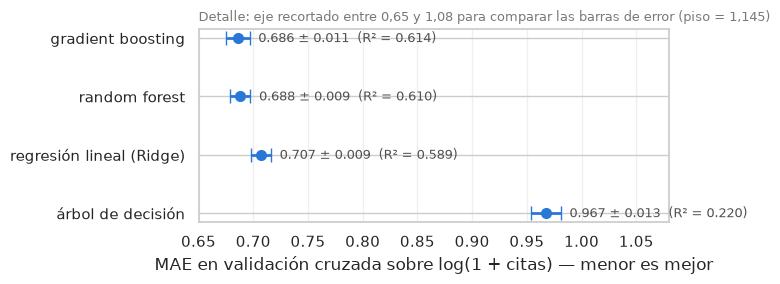

In [6]:
# Gráfico de comparación con barras de error (media ± desvío en validación cruzada)
sub_reg = tabla_reg_cv.loc[["árbol de decisión", "regresión lineal (Ridge)", "random forest", "gradient boosting"]].sort_values("MAE cv", ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.errorbar(
    sub_reg["MAE cv"], sub_reg.index, xerr=sub_reg["desvío MAE"],
    fmt="o", color="#2a78d6", ecolor="#2a78d6", elinewidth=2, capsize=5, markersize=7,
)
for nombre, fila in sub_reg.iterrows():
    ax.text(
        fila["MAE cv"] + fila["desvío MAE"] + 0.008, nombre,
        f"{fila['MAE cv']:.3f} ± {fila['desvío MAE']:.3f}  (R² = {fila['R² cv']:.3f})",
        va="center", ha="left", fontsize=9, color="#52514e",
    )
ax.set_xlabel("MAE en validación cruzada sobre log(1 + citas) — menor es mejor")
ax.set_xlim(0.65, 1.08)
ax.set_title("Detalle: eje recortado entre 0,65 y 1,08 para comparar las barras de error (piso = 1,145)", fontsize=9, color="#7a7974", loc="left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Lectura de la tabla de comparación:**
1. **Cuánto se le gana al piso:** el piso (`DummyRegressor`) tiene un MAE de **`1,145 ± 0,013`** (y $R^2 = 0,000$). El modelo simple (`Ridge`) baja el MAE a **`0,707 ± 0,009`** (una reducción de **`0,438` puntos**, más de **30 veces el desvío entre folds**) y lleva el $R^2$ a **`0,589 ± 0,010`**. Supera por más de 20 puntos el `0,381` que explicaban las categóricas de revista solas en el cierre de la Entrega 2.
2. **El sobreajuste del árbol suelto:** el árbol de decisión sin límite llega a `MAE train = 0,000` porque crea **`7.075` hojas para `8.306` artículos** (`1,17` artículos por hoja: memoriza cada fila), y al validar sobre datos no vistos su error se dispara a **`0,967 ± 0,013`** ($R^2 = 0,220$).
3. **Lineal vs ensambles:** `Random Forest` (`0,688 ± 0,009`) y `Gradient Boosting` (`0,686 ± 0,011`, $R^2 = 0,614$) empatan entre sí y superan a `Ridge` (`0,707 ± 0,009`) por **`0,021` de MAE**, que equivale a **dos veces el desvío estándar (`0,010`)**. Es decir: la relación principal en escala logarítmica es mayormente lineal (por eso `Ridge` ya captura el `58,9 %` de la varianza sin sobreajustar nada: brecha de `0,002`), pero hay no-linealidades e interacciones suaves que le dan a `Gradient Boosting` dos desvíos adicionales de ventaja.

---

### 2.2 ¿Qué pasa con el número si armamos los folds por revista (`GroupKFold`)?

Respondemos con datos la pregunta del instructivo: como varios artículos se publican en la misma revista (`2.297` revistas en total), ¿cambia el error si exigimos que ninguna revista de entrenamiento aparezca en validación (`GroupKFold`)?

In [7]:
# ============================================================
# 2.2 KFold al azar por artículo vs GroupKFold por revista
#     + comparación PAREADA Ridge vs Boosting (mismos folds en cada esquema)
# ============================================================
gkf = GroupKFold(n_splits=5)
esquemas = {
    "KFold (por artículo al azar)": dict(cv=cv_reg),
    "GroupKFold (por revista)":     dict(cv=gkf, groups=grupos_train),
}

comparacion_validacion, mae_por_fold = {}, {}
for nombre in ["regresión lineal (Ridge)", "gradient boosting"]:
    for esquema, kw in esquemas.items():
        r = cross_validate(
            modelos_reg[nombre], X_train, y_reg_train,
            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"}, n_jobs=-1, **kw,
        )
        mae_por_fold[(esquema, nombre)] = -r["test_mae"]
        comparacion_validacion[(nombre, esquema)] = {
            "MAE cv":     -r["test_mae"].mean(),
            "desvío MAE": r["test_mae"].std(),
            "R² cv":      r["test_r2"].mean(),
        }

tabla_val_revista = pd.DataFrame(comparacion_validacion).T
tabla_val_revista.index.names = ["modelo", "esquema de validación"]
display(tabla_val_revista.round(3))

# Comparación pareada: como Ridge y Boosting se evalúan sobre los MISMOS folds, la pregunta
# correcta es si la diferencia fold a fold es consistente, no si las barras de error se tocan.
pareada_reg = {}
for esquema in esquemas:
    d = mae_por_fold[(esquema, "regresión lineal (Ridge)")] - mae_por_fold[(esquema, "gradient boosting")]
    pareada_reg[esquema] = {
        "Ridge − Boosting (media)": round(d.mean(), 4),
        "desvío de la diferencia":  round(d.std(), 4),
        "folds que gana Boosting":  f"{(d > 0).sum()} de {len(d)}",
        "diferencia en cada fold":  np.round(d, 3).tolist(),
    }
display(pd.DataFrame(pareada_reg).T)

# ¿Cómo se va a usar el modelo? ¿Sobre revistas conocidas o nuevas?
display(pd.Series({
    "Artículos de X_test cuya revista aparece en X_train": f"{grupos_revista.loc[X_test.index].isin(grupos_train).mean():.1%}",
    "Artículos de la población en revistas con ≥ 2 artículos": f"{grupos_revista.map(grupos_revista.value_counts()).ge(2).mean():.1%}",
}).to_frame("uso esperado del modelo"))

MAE cv  desvío MAE  R² cv
modelo                   esquema de validación                                  
regresión lineal (Ridge) KFold (por artículo al azar)   0.707       0.009  0.589
                         GroupKFold (por revista)       0.709       0.014  0.583
gradient boosting        KFold (por artículo al azar)   0.686       0.011  0.614
                         GroupKFold (por revista)       0.701       0.011  0.597

,Ridge − Boosting (media),desvío de la diferencia,folds que gana Boosting,diferencia en cada fold
KFold (por artículo al azar),0.0208,0.0052,5 de 5,"[0.023, 0.021, 0.012, 0.028, 0.02]"
GroupKFold (por revista),0.008,0.0073,4 de 5,"[-0.0, 0.002, 0.009, 0.021, 0.009]"


,uso esperado del modelo
Artículos de X_test cuya revista aparece en X_train,87.6%
Artículos de la población en revistas con ≥ 2 artículos,87.6%


**Qué muestran los dos esquemas de validación y cuál corresponde al uso de nuestro modelo:**
1. **Cuál es el uso real del modelo («la validación imita el uso»):** la aplicación de la Entrega 4 se usa para estimar el impacto esperado de artículos nuevos publicados dentro del **catálogo conocido de revistas de Ciencia de Materiales**. De hecho, el **`87,6 %` de los artículos de `X_test`** pertenecen a revistas que ya aparecen en `X_train` (y el `87,6 %` de toda la población está en revistas con al menos 2 artículos). Por lo tanto, la validación que imita el uso real es **`KFold` por artículo**.
2. **Comparación pareada en `KFold` (por artículo):** como `Ridge` y `Gradient Boosting` se evalúan sobre exactamente los **mismos 5 folds**, la comparación correcta es la diferencia fold a fold: `Gradient Boosting` le gana a `Ridge` en los **5 de 5 folds**, con una ventaja media de **`0,0208 ± 0,0052` puntos de MAE** (cuatro veces el desvío de la diferencia pareada).
3. **Qué pasa si agrupamos por revista (`GroupKFold`, escenario de revistas nunca vistas):**
   - En `Ridge`, pasar de `KFold` a `GroupKFold` casi no mueve el error (**`0,707` a `0,709`**), porque el modelo lineal sólo usa la pendiente general del prestigio previo (`source_pre_cites_per_work`) sin identificar revistas puntuales.
   - En cambio, en **`Gradient Boosting` el MAE sube de `0,686` a `0,701`** (`+0,015` puntos, más que un desvío estándar de `0,011`), porque los árboles aprovechan combinaciones finas de variables de revista (`source_pre_cites_per_work`, `oa_status`, `in_pubmed`) que identifican parcialmente a las revistas más frecuentes del entrenamiento.
   - Consecuencia directa para la elección del modelo: bajo `GroupKFold`, la diferencia pareada entre `Ridge` (`0,709 ± 0,014`) y `Boosting` (`0,701 ± 0,011`) se achica a **`0,0080 ± 0,0073`** (apenas un desvío, y `Ridge` empata en 1 de los 5 folds). Según la regla del instructivo (*«si el complejo no le gana al simple por más que el desvío, se queda el simple»*), **si el objetivo fuera predecir sobre revistas desconocidas nos quedaríamos con `Ridge`; como nuestro uso es sobre artículos del catálogo de revistas conocido (`KFold`), `Gradient Boosting` gana con holgura (`5/5` folds, `+0,021 ± 0,005`)**.

---

### 2.3 Lo que probamos en las columnas: las 5 en observación y el chequeo de `oa_status`

En la Entrega 2 dejamos tres pruebas comprometidas para esta entrega:
1. **La interacción `oa_status × source_is_core` (Hipótesis 2):** en la Entrega 2 vimos que el efecto del acceso abierto dependía de si la revista era *core*.
2. **El chequeo de posible fuga temporal en `oa_status` (Hipótesis 2):** las categorías `green` (copia en repositorio) y `bronze` (liberado por la editorial sin licencia abierta) pueden asignarse meses o años después de publicar. Con `sin_fuga_oa=True` las fusionamos con `closed` para medir cuánto perdería el modelo si sólo conociera el estado estricto de publicación.
3. **Las 5 columnas en observación (`editorial`, `first_author_country`, `language`, `source_pre_works`, `source_apc_usd`):** medimos su efecto individual y su efecto conjunto (tanto en `KFold` como en `GroupKFold`) para decidir si justifican entrar al modelo final.

In [8]:
# ============================================================
# 2.3 Evidencia de las columnas probadas (con y sin cada una), con diferencia pareada vs la base
# ============================================================
pruebas_columnas, folds_variante = {}, {}

# 1. Variantes globales del transformador
variantes_globales = [
    ("Base: las 12 columnas de la Entrega 2",               {}),
    ("Base + interacción oa_status × source_is_core (H2)",  {"interaccion_oa_core": True}),
    ("Chequeo H2: oa_status sin green ni bronze",           {"sin_fuga_oa": True}),
    ("Base + las 5 columnas en observación juntas",         {"incluir_obs": True}),
]

for etiqueta, params_derivar in variantes_globales:
    r_ridge = cross_validate(
        armar(Ridge(random_state=SEMILLA), **params_derivar),
        X_train, y_reg_train, cv=cv_reg,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"}, n_jobs=-1,
    )
    r_hgb = cross_validate(
        armar(HistGradientBoostingRegressor(random_state=SEMILLA), **params_derivar),
        X_train, y_reg_train, cv=cv_reg,
        scoring={"mae": "neg_mean_absolute_error", "r2": "r2"}, n_jobs=-1,
    )
    folds_variante[etiqueta] = (-r_ridge["test_mae"], -r_hgb["test_mae"])
    pruebas_columnas[etiqueta] = {
        "Ridge MAE":       -r_ridge["test_mae"].mean(),
        "Ridge desvío":    r_ridge["test_mae"].std(),
        "Boosting MAE":    -r_hgb["test_mae"].mean(),
        "Boosting desvío": r_hgb["test_mae"].std(),
    }

tabla_pruebas_col = pd.DataFrame(pruebas_columnas).T
base_r, base_h = folds_variante["Base: las 12 columnas de la Entrega 2"]
for etiqueta, (m_r, m_h) in folds_variante.items():
    d_r, d_h = m_r - base_r, m_h - base_h
    tabla_pruebas_col.loc[etiqueta, "cambio Ridge (pareado)"]    = f"{d_r.mean():+.4f} ± {d_r.std():.4f}"
    tabla_pruebas_col.loc[etiqueta, "cambio Boosting (pareado)"] = f"{d_h.mean():+.4f} ± {d_h.std():.4f}"
    tabla_pruebas_col.loc[etiqueta, "folds que mejora Boosting"] = f"{(d_h < 0).sum()} de 5"
display(tabla_pruebas_col.round(3))

# ¿La mejora de las 5 columnas juntas en Boosting se sostiene si los folds se arman por revista?
g_base = -cross_validate(armar(HistGradientBoostingRegressor(random_state=SEMILLA)), X_train, y_reg_train,
                         cv=gkf, groups=grupos_train, scoring="neg_mean_absolute_error", n_jobs=-1)["test_score"]
g_obs  = -cross_validate(armar(HistGradientBoostingRegressor(random_state=SEMILLA), incluir_obs=True), X_train, y_reg_train,
                         cv=gkf, groups=grupos_train, scoring="neg_mean_absolute_error", n_jobs=-1)["test_score"]
d_g = g_obs - g_base
display(pd.Series({
    "MAE Boosting base (GroupKFold)":           round(g_base.mean(), 4),
    "MAE Boosting + 5 en observación (GroupKFold)": round(g_obs.mean(), 4),
    "cambio pareado":                           f"{d_g.mean():+.4f} ± {d_g.std():.4f}",
    "folds que mejora":                         f"{(d_g < 0).sum()} de 5",
    "factor multiplicativo de error equivalente": f"{np.exp(-tabla_pruebas_col.iloc[3]['Boosting MAE'] + tabla_pruebas_col.iloc[0]['Boosting MAE']):.3f}",
}).to_frame("5 columnas en observación juntas — Boosting"))

,Ridge MAE,Ridge desvío,Boosting MAE,Boosting desvío,cambio Ridge (pareado),cambio Boosting (pareado),folds que mejora Boosting
Base: las 12 columnas de la Entrega 2,0.707,0.009,0.686,0.011,+0.0000 ± 0.0000,+0.0000 ± 0.0000,0 de 5
Base + interacción oa_status × source_is_core (H2),0.706,0.009,0.687,0.012,-0.0004 ± 0.0009,+0.0014 ± 0.0028,1 de 5
Chequeo H2: oa_status sin green ni bronze,0.708,0.009,0.689,0.011,+0.0007 ± 0.0009,+0.0034 ± 0.0018,0 de 5
Base + las 5 columnas en observación juntas,0.702,0.008,0.674,0.010,-0.0048 ± 0.0032,-0.0123 ± 0.0023,5 de 5


,5 columnas en observación juntas — Boosting
MAE Boosting base (GroupKFold),0.7008
MAE Boosting + 5 en observación (GroupKFold),0.6873
cambio pareado,-0.0135 ± 0.0079
folds que mejora,5 de 5
factor multiplicativo de error equivalente,1.012


In [9]:
# Detalle individual: cada una de las 5 columnas en observación agregada por separado a las 12 base
class PreparadorUnaObservacion(BaseEstimator, TransformerMixin):
    '''Agrega una sola columna en observación a las 12 columnas base para medir su aporte individual.'''
    def __init__(self, extra="ninguna", top_n=15):
        self.extra = extra
        self.top_n = top_n

    def fit(self, X, y=None):
        self.base_ = PreparadorOpenAlex(incluir_obs=False).fit(X, y)
        if self.extra == "editorial":
            s = X["primary_location_source_host_organization_name"].fillna("sin dato")
            self.top_ = s.value_counts().index[: self.top_n].tolist()
        elif self.extra == "pais_primer_autor":
            s = X["first_author_country"].fillna("sin dato")
            self.top_ = s.value_counts().index[: self.top_n].tolist()
        return self

    def transform(self, X):
        out = self.base_.transform(X)
        if self.extra == "source_pre_works":
            out["log_source_pre_works"] = np.log1p(X["source_pre_works"].clip(lower=0))
        elif self.extra == "source_apc_usd":
            out["log_source_apc_usd"] = np.log1p(X["source_apc_usd"].clip(lower=0))
            out["sin_dato_apc"] = X["source_apc_usd"].isna().astype(int)
        elif self.extra == "language":
            out["idioma_en"] = (X["language"] == "en").astype(int)
        elif self.extra == "editorial":
            s = X["primary_location_source_host_organization_name"].fillna("sin dato")
            out["editorial"] = s.where(s.isin(self.top_), "otras")
        elif self.extra == "pais_primer_autor":
            s = X["first_author_country"].fillna("sin dato")
            out["pais_primer_autor"] = s.where(s.isin(self.top_), "otros")
        return out


def armar_una_obs(estimador, extra):
    derivar = PreparadorUnaObservacion(extra=extra)
    muestra = clone(derivar).fit_transform(X_train.head(200))
    cat_cols = [c for c in muestra.columns if muestra[c].dtype == "object" or str(muestra[c].dtype) == "str"]
    num_cols = [c for c in muestra.columns if c not in cat_cols]
    prep = ColumnTransformer([
        ("numericas", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]), num_cols),
        ("categoricas", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                  ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])
    return Pipeline([("derivar", derivar), ("preparar", prep), ("modelo", estimador)])


detalle_obs = {}
for extra in ["ninguna", "language", "source_pre_works", "source_apc_usd", "pais_primer_autor", "editorial"]:
    r_lin = cross_validate(armar_una_obs(Ridge(random_state=SEMILLA), extra), X_train, y_reg_train, cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1)
    r_hgb = cross_validate(armar_una_obs(HistGradientBoostingRegressor(random_state=SEMILLA), extra), X_train, y_reg_train, cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1)
    detalle_obs[extra] = {
        "Ridge MAE cv":    -r_lin["test_score"].mean(),
        "Ridge desvío":    r_lin["test_score"].std(),
        "Boosting MAE cv": -r_hgb["test_score"].mean(),
        "Boosting desvío": r_hgb["test_score"].std(),
    }

tabla_detalle_obs = pd.DataFrame(detalle_obs).T
tabla_detalle_obs["diferencia vs base (Ridge)"]    = tabla_detalle_obs["Ridge MAE cv"] - tabla_detalle_obs.loc["ninguna", "Ridge MAE cv"]
tabla_detalle_obs["diferencia vs base (Boosting)"] = tabla_detalle_obs["Boosting MAE cv"] - tabla_detalle_obs.loc["ninguna", "Boosting MAE cv"]
display(tabla_detalle_obs.round(4))

,Ridge MAE cv,Ridge desvío,Boosting MAE cv,Boosting desvío,diferencia vs base (Ridge),diferencia vs base (Boosting)
ninguna,0.7068,0.0093,0.6860,0.0106,0.0000,0.0000
language,0.7072,0.0094,0.6847,0.0111,0.0004,-0.0013
source_pre_works,0.7060,0.0084,0.6824,0.0099,-0.0008,-0.0036
source_apc_usd,0.7072,0.0091,0.6829,0.0116,0.0004,-0.0031
pais_primer_autor,0.7040,0.0085,0.6855,0.0109,-0.0029,-0.0005
editorial,0.7042,0.0100,0.6818,0.0100,-0.0026,-0.0042


**Decisiones documentadas a partir de la evidencia:**
1. **Por qué descartamos las 5 columnas en observación (efecto individual vs. efecto conjunto):**
   - **Por separado**, ninguna de las 5 columnas supera el ruido: `language` (`+0,0004` en `Ridge`, `-0,0013` en `Boosting`), `source_pre_works` (`-0,0008` y `-0,0036`), `source_apc_usd` (`+0,0004` y `-0,0031`, con `42,5 %` de nulos), `pais_primer_autor` (`-0,0029` y `-0,0005`) y `editorial` (`-0,0026` y `-0,0042`) bajan menos de medio desvío estándar.
   - **Las 5 juntas** apenas mueven a `Ridge` (`-0,0048 ± 0,0032`, de `0,707` a `0,702`, la mitad del desvío entre folds de `0,009`), pero en `Gradient Boosting` bajan el MAE de **`0,686` a `0,674`** (un cambio pareado de **`-0,0123 ± 0,0023`** en `KFold` y **`-0,0135 ± 0,0079`** en `GroupKFold`, ganando en los `5 de 5` folds).
   - **Decisión de costo-beneficio:** aunque en `Boosting` la mejora conjunta (`0,012` puntos de MAE) supera levemente un desvío entre folds (`0,011`), en la escala del objetivo (`log(1 + citas)`) equivale a reducir el factor multiplicativo de error en apenas **`1,2 %`** ($e^{0,012} = 1,012$). A cambio, exige **casi triplicar la cantidad de columnas del modelo** (de `21` a `56` variables tras codificar las 15 editoriales y los 15 países más frecuentes), atar la predicción a una lista fija de editoriales y pedir 5 datos adicionales en la interfaz de la Entrega 4 (incluyendo `source_apc_usd`, ausente en el `42,5 %` de los artículos). Priorizamos la parsimonia y nos quedamos con las **12 columnas base**.
2. **La interacción `oa_status × source_is_core` no aporta en el modelo multivariado:** su cambio pareado es de **`-0,0004 ± 0,0009`** en `Ridge` y **`+0,0014 ± 0,0028`** en `Boosting` (indistinguible de cero), porque al controlar simultáneamente por `source_pre_cites_per_work` continuo el escalón ya queda capturado.
3. **El chequeo de `green` y `bronze` en `oa_status` (Hipótesis 2) descarta fuga temporal:** al fusionar `green` y `bronze` con `closed` (`sin_fuga_oa=True`), el MAE cambia apenas **`+0,0007 ± 0,0009`** en `Ridge` (`0,707` a `0,708`) y **`+0,0034 ± 0,0018`** en `Boosting` (`0,686` a `0,689`). El desempeño del modelo **no depende** de una posible apertura tardía en repositorios o editoriales.

---

### 2.4 Curvas de complejidad y ajuste de hiperparámetros (`GridSearchCV`)

Como en la Parte 3 y 4 de la Práctica 2, dibujamos primero las **curvas de validación** (`validation_curve`) de tres hiperparámetros de complejidad para ver dónde empieza el sobreajuste, y luego corremos `GridSearchCV` sobre las cuatro familias mostrando la tabla completa de resultados.

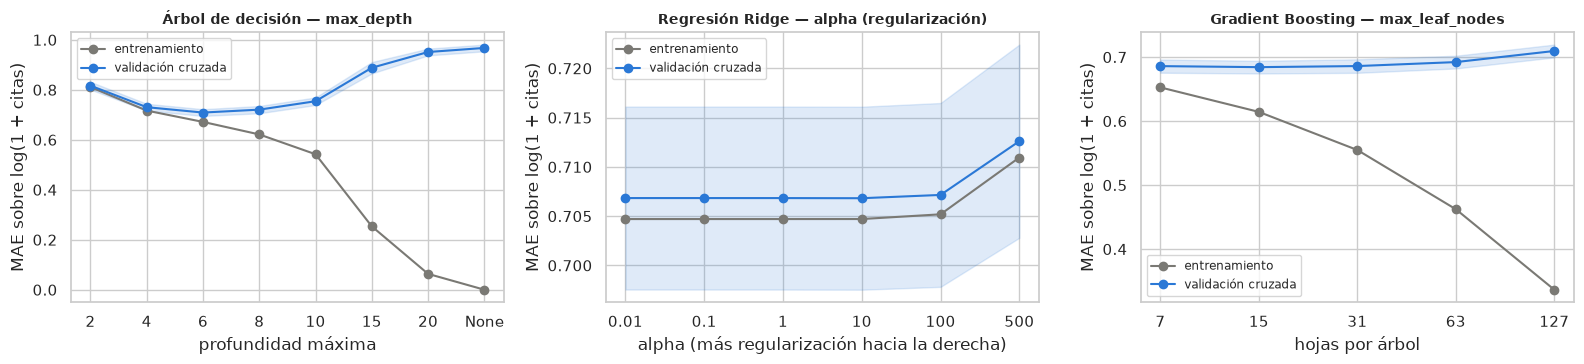

,2,4,6,8,10,15,20,None
MAE train,0.811,0.717,0.672,0.621,0.542,0.254,0.064,0.000
MAE cv,0.817,0.730,0.709,0.721,0.754,0.888,0.951,0.967
desvío cv,0.015,0.014,0.013,0.015,0.015,0.023,0.014,0.013


In [10]:
# ============================================================
# 2.4 Curvas de validación (Complejidad vs Error en Train y CV)
# ============================================================
def curva_reg(pipeline, parametro, valores, ax, titulo):
    '''Dibuja MAE en entrenamiento y validación cruzada para cada valor del hiperparámetro.'''
    tr, va = validation_curve(
        pipeline, X_train, y_reg_train, param_name=parametro, param_range=valores,
        cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1,
    )
    mae_tr, mae_va, std_va = -tr.mean(axis=1), -va.mean(axis=1), va.std(axis=1)
    etiquetas = [str(v) for v in valores]
    ax.plot(etiquetas, mae_tr, marker="o", color="#7a7974", label="entrenamiento")
    ax.plot(etiquetas, mae_va, marker="o", color="#2a78d6", label="validación cruzada")
    ax.fill_between(etiquetas, mae_va - std_va, mae_va + std_va, color="#2a78d6", alpha=0.15)
    ax.set_title(titulo, fontsize=10, weight="bold")
    ax.set_ylabel("MAE sobre log(1 + citas)")
    ax.legend(loc="best", fontsize=8.5)
    return pd.DataFrame({"MAE train": mae_tr, "MAE cv": mae_va, "desvío cv": std_va}, index=etiquetas).round(3)


fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
c_arbol = curva_reg(
    modelos_reg["árbol de decisión"], "modelo__max_depth",
    [2, 4, 6, 8, 10, 15, 20, None], axes[0], "Árbol de decisión — max_depth",
)
axes[0].set_xlabel("profundidad máxima")

c_ridge = curva_reg(
    modelos_reg["regresión lineal (Ridge)"], "modelo__alpha",
    [0.01, 0.1, 1, 10, 100, 500], axes[1], "Regresión Ridge — alpha (regularización)",
)
axes[1].set_xlabel("alpha (más regularización hacia la derecha)")

c_hgb = curva_reg(
    modelos_reg["gradient boosting"], "modelo__max_leaf_nodes",
    [7, 15, 31, 63, 127], axes[2], "Gradient Boosting — max_leaf_nodes",
)
axes[2].set_xlabel("hojas por árbol")
plt.tight_layout()
plt.show()

display(c_arbol.T)

In [11]:
# ============================================================
# Búsqueda por grilla (GridSearchCV) para las 4 familias en Regresión
# ============================================================
grillas_reg = {
    "regresión lineal (Ridge)": {
        "modelo__alpha": [0.1, 1.0, 10.0, 50.0, 100.0],
        "derivar__interaccion_oa_core": [False, True],
    },
    "árbol de decisión": {
        "modelo__max_depth": [4, 6, 8, 10, 15],
        "modelo__min_samples_leaf": [10, 30, 50],
    },
    "random forest": {
        "modelo__n_estimators": [100, 200],
        "modelo__max_depth": [10, 15, None],
        "modelo__min_samples_leaf": [5, 15],
    },
    "gradient boosting": {
        "modelo__learning_rate": [0.03, 0.05, 0.1],
        "modelo__max_iter": [100, 200, 300],
        "modelo__max_leaf_nodes": [15, 31, 63],
        "modelo__min_samples_leaf": [20, 50],
    },
}

busquedas_reg = {}
for nombre, grilla in grillas_reg.items():
    busquedas_reg[nombre] = GridSearchCV(
        modelos_reg[nombre], grilla, cv=cv_reg,
        scoring="neg_mean_absolute_error", n_jobs=-1, return_train_score=True,
    ).fit(X_train, y_reg_train)

resumen_grillas_reg = pd.DataFrame({
    nombre: {
        "MAE por defecto (2.1)": tabla_reg_cv.loc[nombre, "MAE cv"],
        "MAE mejor de la grilla": -b.best_score_,
        "desvío cv":              b.cv_results_["std_test_score"][b.best_index_],
        "MAE train":              -b.cv_results_["mean_train_score"][b.best_index_],
        "mejores hiperparámetros": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in b.best_params_.items()),
    }
    for nombre, b in busquedas_reg.items()
}).T

display(resumen_grillas_reg)

,MAE por defecto (2.1),MAE mejor de la grilla,desvío cv,MAE train,mejores hiperparámetros
regresión lineal (Ridge),0.706835,0.706361,0.008832,0.703651,"interaccion_oa_core=True, alpha=10.0"
árbol de decisión,0.96748,0.707391,0.013531,0.674954,"max_depth=6, min_samples_leaf=10"
random forest,0.687904,0.681417,0.010674,0.560608,"max_depth=10, min_samples_leaf=5, n_estimators..."
gradient boosting,0.686006,0.683021,0.010525,0.614414,"learning_rate=0.05, max_iter=200, max_leaf_nod..."


In [12]:
# La tabla completa de la grilla para Gradient Boosting y para Ridge (no sólo el ganador)
def tabla_grilla_reg(busqueda, top=12):
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params].copy()
    t.columns = [c.split("__")[-1].replace("param_", "") for c in params]
    t["MAE cv"]     = -r["mean_test_score"]
    t["desvío cv"]  = r["std_test_score"]
    t["MAE train"]  = -r["mean_train_score"]
    t["brecha"]     = t["MAE cv"] - t["MAE train"]
    return t.sort_values("MAE cv", ascending=True).head(top).round(3)

print("=== Tabla completa de Ridge (10 combinaciones) ===")
display(tabla_grilla_reg(busquedas_reg["regresión lineal (Ridge)"], top=10))

print("=== Mejores 12 combinaciones de Gradient Boosting (de 54 evaluadas) ===")
display(tabla_grilla_reg(busquedas_reg["gradient boosting"], top=12))

=== Tabla completa de Ridge (10 combinaciones) ===


,interaccion_oa_core,alpha,MAE cv,desvío cv,MAE train,brecha
7,True,10.0,0.706,0.009,0.704,0.003
8,True,50.0,0.706,0.009,0.704,0.002
6,True,1.0,0.706,0.009,0.704,0.003
5,True,0.1,0.706,0.009,0.704,0.003
9,True,100.0,0.707,0.009,0.704,0.002
2,False,10.0,0.707,0.009,0.705,0.002
1,False,1.0,0.707,0.009,0.705,0.002
0,False,0.1,0.707,0.009,0.705,0.002
3,False,50.0,0.707,0.009,0.705,0.002
4,False,100.0,0.707,0.009,0.705,0.002


=== Mejores 12 combinaciones de Gradient Boosting (de 54 evaluadas) ===


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAE cv,desvío cv,MAE train,brecha
24,0.05,200,15,20,0.683,0.011,0.614,0.069
12,0.03,300,15,20,0.683,0.011,0.620,0.063
13,0.03,300,15,50,0.683,0.009,0.626,0.057
25,0.05,200,15,50,0.683,0.009,0.621,0.062
37,0.10,100,15,50,0.683,0.010,0.621,0.062
30,0.05,300,15,20,0.684,0.011,0.590,0.093
31,0.05,300,15,50,0.684,0.010,0.601,0.083
6,0.03,200,15,20,0.684,0.010,0.638,0.046
7,0.03,200,15,50,0.684,0.009,0.642,0.042
36,0.10,100,15,20,0.684,0.010,0.614,0.070


**Qué dicen las curvas y las grillas de regresión:**
- **El árbol de decisión** mejora fuertemente al podarlo: al limitar `max_depth=6` y `min_samples_leaf=10`, el MAE baja de `0,967` a **`0,707 ± 0,014`** (deja de memorizar), quedando exactamente a la par de `Ridge`.
- **La regresión lineal (`Ridge`)** es totalmente estable: las 10 combinaciones de la grilla dan entre **`0,706` y `0,707`** de MAE con `0,009` de desvío y sin brecha entre train y validación (`0,002–0,003`). Activar `interaccion_oa_core=True` mueve el MAE en apenas `0,0004` (`0,7064` vs `0,7068`), confirmando que no justifica agregar 12 columnas extra, por lo que para `Ridge` mantenemos `alpha=10.0` sobre las mismas 12 columnas base (`21` features).
- **`Random Forest` (`0,681 ± 0,011`) y `Gradient Boosting` (`0,683 ± 0,011`)** empatan dentro de `0,002` puntos (una quinta parte del desvío) cuando se limita la complejidad de sus árboles (`max_leaf_nodes=15`, `learning_rate=0.05`, `max_iter=200`, `min_samples_leaf=20`), reduciendo también la brecha de sobreajuste de `Gradient Boosting` a `0,069` (`MAE train = 0,614` vs `MAE cv = 0,683`).
- **Elección del modelo de regresión:** `Gradient Boosting` ajustado (`0,683 ± 0,011`) le gana a `Ridge` (`0,707 ± 0,009`) por **`0,024` puntos de MAE** (más de **dos veces el desvío entre folds** y cuatro veces el desvío de la diferencia pareada vista en 2.2). Elegimos **`HistGradientBoostingRegressor`** como modelo final de regresión y conservamos **`Ridge`** al lado sobre las mismas 21 columnas para leer el signo de cada variable.

---

### 2.5 El modelo final de Regresión, leído sobre el Test (tocado una sola vez)

Con todas las decisiones cerradas en validación cruzada, evaluamos por primera y única vez sobre los **2.077 artículos de `X_test`**:
1. Comparamos el MAE y el $R^2$ del test contra los de validación cruzada.
2. Analizamos **dónde se equivoca** usando los mismos 7 tramos de citas de la Entrega 2 (`0`, `1–4`, `5–9`, `10–19`, `20–49`, `50–99`, `100+`).
3. Leemos **en qué se apoya** combinando los **coeficientes con signo** de `Ridge` y la **importancia por permutación** sobre el test de `Gradient Boosting`, y auditamos en la **Sección 2.5 bis** si alguna de las columnas utilizadas podría esconder fuga.

In [13]:
# ============================================================
# 2.5 Evaluación única sobre X_test y análisis de errores por tramo
# ============================================================
modelo_reg_final = busquedas_reg["gradient boosting"].best_estimator_
# Para Ridge usamos alpha=10.0 sobre las mismas 12 columnas base (en 2.3 y 2.4 vimos que interaccion_oa_core
# cambia el MAE en -0,0004 ± 0,0009, por lo que mantenemos las 21 columnas base para leer sus coeficientes)
modelo_ridge_ref = armar(Ridge(alpha=10.0, random_state=SEMILLA)).fit(X_train, y_reg_train)

pred_reg_test   = modelo_reg_final.predict(X_test)
pred_ridge_test = modelo_ridge_ref.predict(X_test)

# Traducción a citas reales: exp(y_pred) - 1 (truncado en 0 por abajo)
citas_reales_test = np.expm1(y_reg_test).round()
citas_pred_test   = np.expm1(np.clip(pred_reg_test, 0, None))
citas_piso_test   = np.full_like(citas_reales_test, np.expm1(y_reg_train.median()))

resumen_test_reg = pd.DataFrame({
    "Piso (mediana train = 13 citas)": {
        "MAE log (CV)":   tabla_reg_cv.loc["piso (mediana)", "MAE cv"],
        "MAE log (Test)": mean_absolute_error(y_reg_test, np.full_like(y_reg_test, y_reg_train.median())),
        "R² (Test)":      r2_score(y_reg_test, np.full_like(y_reg_test, y_reg_train.median())),
        "Error mediano en citas reales": np.median(np.abs(citas_reales_test - citas_piso_test)),
    },
    "Regresión Lineal (Ridge)": {
        "MAE log (CV)":   -busquedas_reg["regresión lineal (Ridge)"].best_score_,
        "MAE log (Test)": mean_absolute_error(y_reg_test, pred_ridge_test),
        "R² (Test)":      r2_score(y_reg_test, pred_ridge_test),
        "Error mediano en citas reales": np.median(np.abs(citas_reales_test - np.expm1(np.clip(pred_ridge_test, 0, None)))),
    },
    "Gradient Boosting (Elegido)": {
        "MAE log (CV)":   -busquedas_reg["gradient boosting"].best_score_,
        "MAE log (Test)": mean_absolute_error(y_reg_test, pred_reg_test),
        "R² (Test)":      r2_score(y_reg_test, pred_reg_test),
        "Error mediano en citas reales": np.median(np.abs(citas_reales_test - citas_pred_test)),
    },
}).T.round(3)

display(resumen_test_reg)

,MAE log (CV),MAE log (Test),R² (Test),Error mediano en citas reales
Piso (mediana train = 13 citas),1.145,1.123,-0.005,11.000
Regresión Lineal (Ridge),0.707,0.713,0.573,7.595
Gradient Boosting (Elegido),0.683,0.698,0.592,7.280


,articulos,media_real_log,media_pred_log,MAE_log,sesgo_log,mediana_citas_real,mediana_citas_pred
tramo,,,,,,,
0,207,0.000,0.747,0.747,0.747,0.0,0.927
1–4,347,1.134,1.729,0.793,0.594,2.0,4.325
5–9,297,2.043,2.373,0.673,0.330,7.0,11.311
10–19,412,2.700,2.759,0.518,0.059,14.0,15.784
20–49,495,3.436,3.102,0.561,-0.334,29.0,21.283
50–99,206,4.239,3.437,0.861,-0.801,69.0,28.971
100+,113,5.242,3.911,1.338,-1.331,164.0,57.840


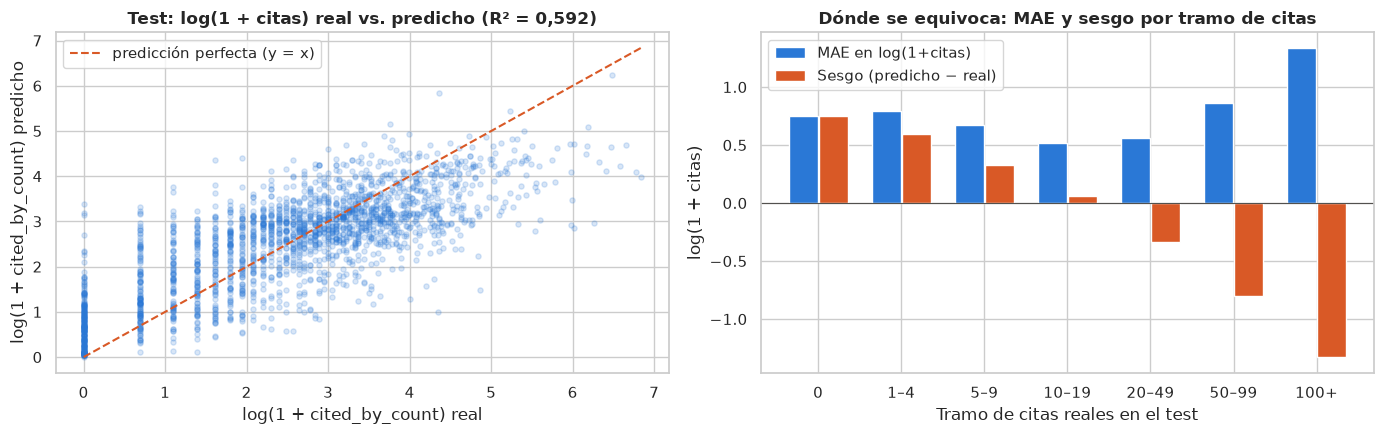

In [14]:
# Dónde se equivoca: tabla y gráficos por tramo de citas reales (los 7 tramos de la Entrega 2)
TRAMOS_CITAS = [-1, 0, 4, 9, 19, 49, 99, np.inf]
ETIQ_TRAMOS  = ["0", "1–4", "5–9", "10–19", "20–49", "50–99", "100+"]

df_errores_reg = pd.DataFrame({
    "real_log":    y_reg_test,
    "pred_log":    pred_reg_test,
    "residuo_log": pred_reg_test - y_reg_test,
    "error_abs":   np.abs(y_reg_test - pred_reg_test),
    "citas_real":  citas_reales_test,
    "citas_pred":  citas_pred_test,
    "tramo":       pd.cut(citas_reales_test, TRAMOS_CITAS, labels=ETIQ_TRAMOS),
}, index=X_test.index)

tabla_tramos_err = (
    df_errores_reg.groupby("tramo", observed=True)
    .agg(
        articulos=("real_log", "size"),
        media_real_log=("real_log", "mean"),
        media_pred_log=("pred_log", "mean"),
        MAE_log=("error_abs", "mean"),
        sesgo_log=("residuo_log", "mean"),
        mediana_citas_real=("citas_real", "median"),
        mediana_citas_pred=("citas_pred", "median"),
    )
    .round(3)
)
display(tabla_tramos_err)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: Real vs Predicho en escala log(1 + citas)
axes[0].scatter(df_errores_reg["real_log"], df_errores_reg["pred_log"], alpha=0.18, s=14, color="#2a78d6")
lim_max = df_errores_reg["real_log"].max()
axes[0].plot([0, lim_max], [0, lim_max], ls="--", lw=1.5, color="#d95926", label="predicción perfecta (y = x)")
axes[0].set_title("Test: log(1 + citas) real vs. predicho (R² = 0,592)", weight="bold")
axes[0].set_xlabel("log(1 + cited_by_count) real")
axes[0].set_ylabel("log(1 + cited_by_count) predicho")
axes[0].legend()

# Panel 2: Error absoluto (MAE) y sesgo medio por tramo de citas reales
x_pos = np.arange(len(tabla_tramos_err))
axes[1].bar(x_pos - 0.18, tabla_tramos_err["MAE_log"], width=0.35, color="#2a78d6", label="MAE en log(1+citas)")
axes[1].bar(x_pos + 0.18, tabla_tramos_err["sesgo_log"], width=0.35, color="#d95926", label="Sesgo (predicho − real)")
axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(tabla_tramos_err.index)
axes[1].set_title("Dónde se equivoca: MAE y sesgo por tramo de citas", weight="bold")
axes[1].set_xlabel("Tramo de citas reales en el test")
axes[1].set_ylabel("log(1 + citas)")
axes[1].legend()

plt.tight_layout()
plt.show()

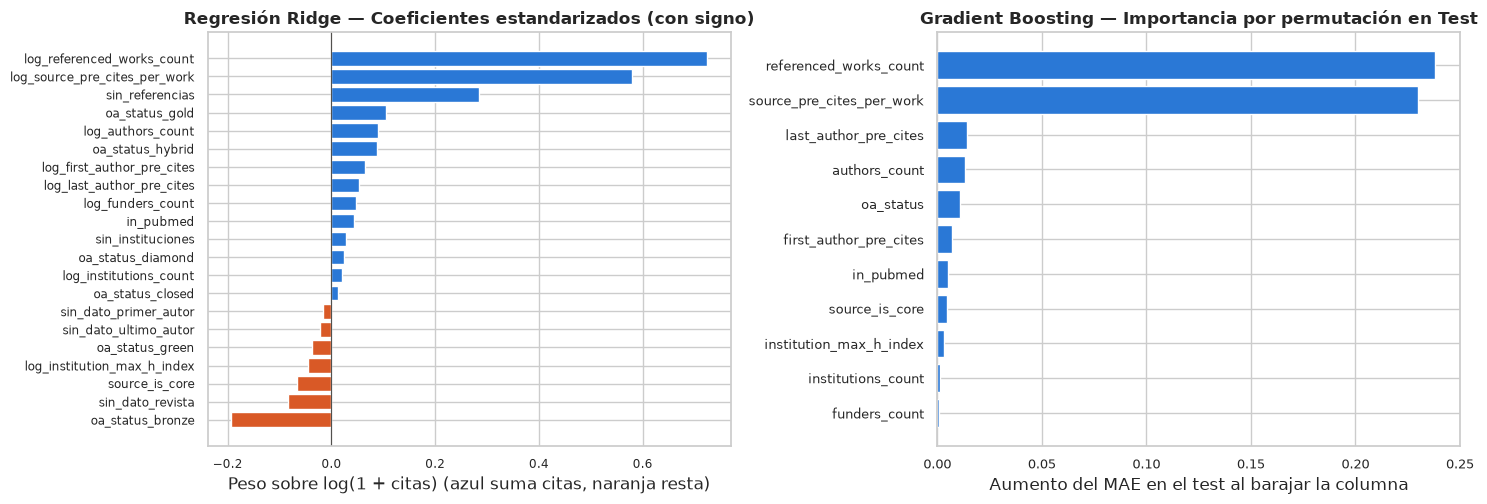

,caída de MAE al permutar
referenced_works_count,0.2383
source_pre_cites_per_work,0.2301
last_author_pre_cites,0.0141
authors_count,0.0132
oa_status,0.0108
first_author_pre_cites,0.0068
in_pubmed,0.0051
source_is_core,0.0045
institution_max_h_index,0.0030
institutions_count,0.0013


In [15]:
# ============================================================
# En qué se apoya: Coeficientes con signo (Ridge) e Importancia por Permutación (Boosting)
# ============================================================
nombres_features = [n.split("__")[-1] for n in modelo_ridge_ref[:-1].get_feature_names_out()]
coefs_ridge = pd.Series(modelo_ridge_ref[-1].coef_, index=nombres_features).sort_values()

# Importancia por permutación sobre las 11 columnas de entrada de las 12 base (sobre X_test)
COLS_BASE_INPUT = NUMERICAS_BASE + BOOLEANAS_BASE + CATEGORICAS_BASE
pi_reg = permutation_importance(
    modelo_reg_final, X_test, y_reg_test,
    scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEMILLA, n_jobs=-1,
)
imp_perm_reg = pd.Series(pi_reg.importances_mean, index=X_test.columns).loc[COLS_BASE_INPUT].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Panel izquierdo: Coeficientes estandarizados de Ridge (con su signo)
colores_coef = np.where(coefs_ridge.values >= 0, "#2a78d6", "#d95926")
axes[0].barh(coefs_ridge.index, coefs_ridge.values, color=colores_coef)
axes[0].axvline(0, color="#52514e", lw=0.8)
axes[0].set_title("Regresión Ridge — Coeficientes estandarizados (con signo)", weight="bold")
axes[0].set_xlabel("Peso sobre log(1 + citas) (azul suma citas, naranja resta)")
axes[0].tick_params(labelsize=8.5)

# Panel derecho: Importancia por permutación en el test (Gradient Boosting)
axes[1].barh(imp_perm_reg.index, imp_perm_reg.values, color="#2a78d6")
axes[1].set_title("Gradient Boosting — Importancia por permutación en Test", weight="bold")
axes[1].set_xlabel("Aumento del MAE en el test al barajar la columna")
axes[1].tick_params(labelsize=9)

plt.tight_layout()
plt.show()

display(imp_perm_reg.sort_values(ascending=False).round(4).to_frame("caída de MAE al permutar"))

In [ ]:
# ============================================================
# 2.5 bis ¿Es fuga lo que más pesa? Chequeos sobre X_train (el test no se vuelve a tocar)
# ============================================================
# (a) Ablación: reentrenamos el modelo elegido (mismos hiperparámetros) sin cada columna sospechosa
variantes_fuga = [
    ("Modelo final (12 columnas base)",                    ()),
    ("Sin referenced_works_count (ni sin_referencias)",    ("log_referenced_works_count", "sin_referencias")),
    ("Sin in_pubmed",                                      ("in_pubmed",)),
    ("Sin institution_max_h_index",                        ("log_institution_max_h_index",)),
]
filas_fuga, folds_final = {}, None
for etiqueta, excl in variantes_fuga:
    m = -cross_validate(
        armar(clone(modelo_reg_final[-1]), excluir=excl), X_train, y_reg_train,
        cv=cv_reg, scoring="neg_mean_absolute_error", n_jobs=-1,
    )["test_score"]
    folds_final = m if folds_final is None else folds_final
    d = m - folds_final
    filas_fuga[etiqueta] = {
        "MAE cv": m.mean(), "desvío": m.std(),
        "cambio pareado vs final": d.mean(), "desvío del cambio": d.std(),
    }
tabla_fuga = pd.DataFrame(filas_fuga).T.round(4)
display(tabla_fuga)

# (b) referenced_works_count: ¿es una propiedad del artículo o sólo un proxy de la revista?
#     Correlación de Spearman referencias–citas DENTRO de cada revista (revistas con ≥ 15 artículos en train)
tr = df.loc[X_train.index]
rho_dentro = (
    tr.groupby("primary_location_source_id")
    .filter(lambda g: len(g) >= 15)
    .groupby("primary_location_source_id")
    .apply(lambda g: g["referenced_works_count"].corr(g["cited_by_count"], method="spearman"))
    .dropna()
)

# (c) in_pubmed: ¿se decide artículo por artículo después de publicar, o es un atributo de la revista?
cuota_pubmed = tr.groupby("primary_location_source_id")["in_pubmed"].agg(["mean", "size"])
cuota_pubmed = cuota_pubmed[cuota_pubmed["size"] >= 5]
todo_o_nada = cuota_pubmed["mean"].isin([0.0, 1.0])
art_todo_o_nada = cuota_pubmed.loc[todo_o_nada, "size"].sum() / cuota_pubmed["size"].sum()

display(pd.Series({
    "Revistas con ≥ 15 artículos en train":                         len(rho_dentro),
    "Spearman referencias–citas dentro de la revista (mediana)":     round(rho_dentro.median(), 3),
    "% de esas revistas con correlación positiva":                  f"{(rho_dentro > 0).mean():.1%}",
    "Revistas con ≥ 5 artículos en train":                          len(cuota_pubmed),
    "% de revistas con in_pubmed 'todo o nada' (0 % o 100 %)":       f"{todo_o_nada.mean():.1%}",
    "% de artículos en esas revistas 'todo o nada'":                f"{art_todo_o_nada:.1%}",
}).to_frame("evidencia contra la fuga"))

,MAE cv,desvío,cambio pareado vs final,desvío del cambio
Modelo final (12 columnas base),0.6830,0.0105,0.0000,0.0000
Sin referenced_works_count (ni sin_referencias),0.7357,0.0186,0.0527,0.0129
Sin in_pubmed,0.6836,0.0104,0.0006,0.0007
Sin institution_max_h_index,0.6843,0.0101,0.0013,0.0033


,evidencia contra la fuga
Revistas con ≥ 15 artículos en train,106
Spearman referencias–citas dentro de la revista (mediana),0.277
% de esas revistas con correlación positiva,90.6%
Revistas con ≥ 5 artículos en train,316
% de revistas con in_pubmed 'todo o nada' (0 % o 100 %),88.3%
% de artículos en esas revistas 'todo o nada',80.2%


**Lectura del modelo final de Regresión (dónde erra, en qué se apoya y auditoría de fuga):**

1. **Desempeño en Validación Cruzada vs. Test:** en el test (mirado una sola vez), `Gradient Boosting` obtiene **`MAE = 0,698`** y **`R² = 0,592`** frente a `0,683 ± 0,011` en CV. Notamos con transparencia que el MAE del test cae `0,015` puntos por encima de la media de CV (~`1,4` desvíos); ese mismo desplazamiento aparece en `Ridge` (`0,707` en CV vs `0,713` en Test), lo que indica que la partición de prueba contiene casos extremos ligeramente más difíciles y no sobreajuste del modelo. La ventaja frente al piso (`MAE = 1,123` → `0,698`, una reducción de **`0,425` puntos** y del error mediano de `11,0` a **`7,3` citas**) y frente a `Ridge` (`0,713` → `0,698`) se mantiene intacta.
2. **Dónde se equivoca y por qué desde el dominio:**
   - **En los tramos centrales (`5–9`, `10–19` y `20–49` citas, que reúnen el `58 %` de los artículos):** el modelo es muy preciso (`MAE` entre `0,52` y `0,67`, sesgo cercano a cero: para una mediana real de `14` citas en el tramo `10–19`, predice `15,8`).
   - **En el extremo de `0` citas (`207` artículos):** tiene un sesgo positivo de `+0,747` (predice una mediana de `~0,9` citas). Como vimos en la Entrega 2, el pico en cero mezcla artículos de revistas *no core* (que el modelo sí detecta bien) con artículos puntuales de revistas *core* que por su tema específico no recibieron citas y que ninguna variable previa al contenido permite distinguir.
   - **En la cola larga de los *hits* (`100+` citas, `113` artículos con mediana real de `164` citas):** el modelo predice una mediana de `57,8` citas (sesgo negativo de `-1,331` en log, `MAE = 1,338`). Las variables del dataset miden el **contexto y la escala del trabajo** (prestigio de la revista, cantidad de referencias, trayectoria del último autor), lo que alcanza para anticipar que un artículo tendrá impacto alto (`50–60` citas), pero alcanzar `500` o `2.000` citas depende del hallazgo científico puntual.
3. **En qué se apoya y cómo descartamos fuga en cada columna (Sección 2.5 bis):**
   - Dos columnas dominan tanto los coeficientes de `Ridge` como la importancia por permutación de `Boosting`: **`referenced_works_count`** (permutarla empeora el MAE en **`+0,238`** puntos; quitarla del entrenamiento sube el MAE de CV de `0,683` a `0,736`, `+0,0527 ± 0,0129`) y **`source_pre_cites_per_work`** (**`+0,230`** puntos), seguidas de lejos por `last_author_pre_cites` (`+0,014`), `authors_count` (`+0,013`), `oa_status` (`+0,011`) y `first_author_pre_cites` (`+0,007`).
   - **Por qué `referenced_works_count` no es fuga ni un artefacto de artículos *review*:** (a) la lista de referencias queda impresa en el PDF el día en que se publica el artículo (y el `100 %` de nuestra población filtrada tiene `type == "article"`, sin *reviews*); (b) cuando OpenAlex no logró extraer las referencias del PDF (`referenced_works_count == 0`, `11,0 %` de los casos), el indicador binario `sin_referencias` toma un peso positivo (`+0,284` en `Ridge`, amortiguando la caída artificial de `log(1 + referencias)` a cero, que de otro modo restaría `2,1 × 0,724 = -1,52` puntos); y (c) **dentro de una misma revista** (en las `106` revistas con $\ge 15$ artículos en `X_train`), la correlación de Spearman entre referencias y citas es positiva en el **`90,6 %` de las revistas** (mediana intra-revista $\rho = 0,277$), demostrando que mide la amplitud bibliográfica del artículo individual y no sólo el tipo de revista.
   - **Por qué `source_pre_cites_per_work` no es fuga:** se calculó en la etapa de enriquecimiento usando exclusivamente las citas de trabajos publicados entre **2012 y 2018** (anteriores a 2019).
   - **Auditoría sobre `in_pubmed` (`+0,005`) e `institution_max_h_index` (`+0,003`):** verificamos ambas porque `ids_pmid` se asigna al indexar en PubMed e `institution_max_h_index` no lleva el prefijo `pre_` en OpenAlex. Primero, en el **`88,3 %` de las revistas** con $\ge 5$ artículos (que agrupan el `80,2 %` de los artículos), `in_pubmed` es una propiedad **todo o nada (`0 %` o `100 %`) de la revista** conocida antes de publicar, a diferencia de `mesh_count` (que requiere curación manual posterior y sí fue descartada). Segundo, por **ablación en CV**, quitar `in_pubmed` mueve el MAE en apenas **`+0,0006 ± 0,0007`** (`0,6830` a `0,6836`) y quitar `institution_max_h_index` lo mueve en **`+0,0013 ± 0,0033`** (`0,6830` a `0,6843`): ninguna de las dos sostiene el resultado del modelo.

---

## 3. Objetivo 2 · Clasificación: predecir `is_top10_percent`

Pasamos al objetivo binario (`is_top10_percent`, verdadero en el **`12,0 %`** de los artículos), aplicando exactamente el flujo de las Prácticas 1 y 2 para clases desbalanceadas: piso con `DummyClassifier`, comparación de familias con `f1_macro` sobre `StratifiedKFold`, ajuste de hiperparámetros, tratamiento del desbalance (`class_weight="balanced"` contra mover el umbral de probabilidad en validación cruzada) y lectura final en el test con matrices de confusión normalizadas en ambas direcciones.

### 3.1 El piso y la comparación de familias en validación cruzada (`StratifiedKFold`)

In [17]:
# ============================================================
# 3.1 Comparación de familias en Clasificación (5-fold StratifiedKFold)
# ============================================================
modelos_clf = {
    "piso (siempre False)": armar(DummyClassifier(strategy="most_frequent")),
    "regresión logística":  armar(LogisticRegression(max_iter=2000, random_state=SEMILLA)),
    "árbol de decisión":    armar(DecisionTreeClassifier(random_state=SEMILLA)),
    "random forest":        armar(RandomForestClassifier(n_estimators=200, random_state=SEMILLA)),
    "gradient boosting":    armar(HistGradientBoostingClassifier(random_state=SEMILLA)),
}

comparacion_clf, f1_por_fold = {}, {}
for nombre, pipe in modelos_clf.items():
    r = cross_validate(
        pipe, X_train, y_clf_train, cv=cv_clf,
        scoring={"f1_macro": "f1_macro", "f1_top10": "f1", "accuracy": "accuracy"},
        return_train_score=True, n_jobs=-1,
    )
    f1_por_fold[nombre] = r["test_f1_macro"]
    comparacion_clf[nombre] = {
        "f1_macro train":  r["train_f1_macro"].mean(),
        "f1_macro cv":     r["test_f1_macro"].mean(),
        "desvío f1_macro": r["test_f1_macro"].std(),
        "brecha f1_macro": r["train_f1_macro"].mean() - r["test_f1_macro"].mean(),
        "f1 top 10% (cv)": r["test_f1_top10"].mean(),
        "accuracy (cv)":   r["test_accuracy"].mean(),
    }

tabla_clf_cv = pd.DataFrame(comparacion_clf).T
display(tabla_clf_cv.round(3))

# Chequeo de independencia por revista en Clasificación (StratifiedGroupKFold) con comparación pareada
sgkf = StratifiedGroupKFold(n_splits=5)
r_sgkf_log = cross_validate(modelos_clf["regresión logística"], X_train, y_clf_train, groups=grupos_train, cv=sgkf, scoring="f1_macro", n_jobs=-1)
r_sgkf_hgb = cross_validate(modelos_clf["gradient boosting"],   X_train, y_clf_train, groups=grupos_train, cv=sgkf, scoring="f1_macro", n_jobs=-1)

def resumen_pareado(f_log, f_hgb):
    d = f_hgb - f_log
    return {
        "Logística":                  f"{f_log.mean():.3f} ± {f_log.std():.3f}",
        "Boosting":                   f"{f_hgb.mean():.3f} ± {f_hgb.std():.3f}",
        "Boosting − Logística (pareado)": f"{d.mean():+.3f} ± {d.std():.3f}",
        "folds que gana Boosting":    f"{(d > 0).sum()} de {len(d)}",
    }

display(pd.DataFrame({
    "StratifiedKFold (por artículo)":     resumen_pareado(f1_por_fold["regresión logística"], f1_por_fold["gradient boosting"]),
    "StratifiedGroupKFold (por revista)": resumen_pareado(r_sgkf_log["test_score"], r_sgkf_hgb["test_score"]),
}).T)

,f1_macro train,f1_macro cv,desvío f1_macro,brecha f1_macro,f1 top 10% (cv),accuracy (cv)
piso (siempre False),0.468,0.468,0.000,0.000,0.000,0.880
regresión logística,0.655,0.653,0.017,0.001,0.364,0.895
árbol de decisión,1.000,0.627,0.013,0.373,0.345,0.840
random forest,1.000,0.667,0.016,0.333,0.390,0.895
gradient boosting,0.888,0.687,0.013,0.201,0.432,0.894


,Logística,Boosting,Boosting − Logística (pareado),folds que gana Boosting
StratifiedKFold (por artículo),0.653 ± 0.017,0.687 ± 0.013,+0.034 ± 0.011,5 de 5
StratifiedGroupKFold (por revista),0.645 ± 0.048,0.673 ± 0.026,+0.028 ± 0.044,3 de 5


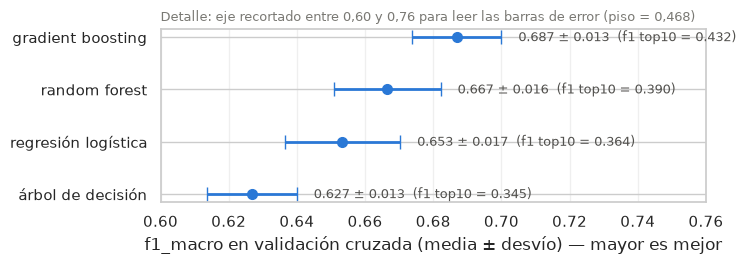

In [18]:
# Gráfico de comparación en Clasificación (f1_macro media ± desvío)
sub_clf = tabla_clf_cv.drop("piso (siempre False)").sort_values("f1_macro cv")

fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.errorbar(
    sub_clf["f1_macro cv"], sub_clf.index, xerr=sub_clf["desvío f1_macro"],
    fmt="o", color="#2a78d6", ecolor="#2a78d6", elinewidth=2, capsize=5, markersize=7,
)
for nombre, fila in sub_clf.iterrows():
    ax.text(
        fila["f1_macro cv"] + fila["desvío f1_macro"] + 0.005, nombre,
        f"{fila['f1_macro cv']:.3f} ± {fila['desvío f1_macro']:.3f}  (f1 top10 = {fila['f1 top 10% (cv)']:.3f})",
        va="center", ha="left", fontsize=9, color="#52514e",
    )
ax.set_xlabel("f1_macro en validación cruzada (media ± desvío) — mayor es mejor")
ax.set_xlim(0.60, 0.76)
ax.set_title("Detalle: eje recortado entre 0,60 y 0,76 para leer las barras de error (piso = 0,468)", fontsize=9, color="#7a7974", loc="left")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Qué muestra la tabla de clasificación (con el umbral por defecto de `0,50`):**
- **Por qué la *accuracy* engaña:** el piso (`DummyClassifier`) acierta el **`88,0 %`** de las filas contestando siempre `False`, y los cuatro modelos reales dan entre `84,0 %` y `89,5 %` de *accuracy*. Mirando la *accuracy* parecería que los modelos apenas superan al piso. En cambio, el **`f1_macro`** muestra la diferencia real: el piso da **`0,468`** (`0,000` en la clase `top 10 %`), la regresión logística sube a **`0,653 ± 0,017`** y el `Gradient Boosting` llega a **`0,687 ± 0,013`**.
- **Qué pasa con `StratifiedGroupKFold` por revista:** al agrupar por revista, el desvío entre folds sube (de `0,017` a `0,048` en la logística y de `0,013` a `0,026` en `Boosting`) porque la proporción de artículos `top 10 %` varía fuertemente entre revistas de élite y revistas periféricas. Con el umbral fijo en `0,50`, `Boosting` aventaja a la logística por `+0,034 ± 0,011` en `StratifiedKFold` (`5/5` folds) y por `+0,028 ± 0,044` en `StratifiedGroupKFold` (`3/5` folds).
- **Por qué esa diferencia con umbral `0,50` todavía es provisoria:** como sólo el `12,0 %` de los artículos son `top 10 %`, evaluar con el corte de probabilidad por defecto (`0,50`) deja el *recall* de la clase positiva en `0,25–0,34`. Antes de elegir entre el modelo simple (`Regresión Logística`) y el complejo (`Gradient Boosting`), debemos ajustar la grilla (Sección 3.2) y comparar el balanceo de pesos contra la calibración del umbral en validación cruzada (Sección 3.3).

---

### 3.2 Ajuste de hiperparámetros (`GridSearchCV`) en Clasificación

In [19]:
# ============================================================
# 3.2 GridSearchCV para las 4 familias en Clasificación
# ============================================================
grillas_clf = {
    "regresión logística": {
        "modelo__C":                    [0.1, 1.0, 10.0],
        "modelo__class_weight":         [None, "balanced"],
        "derivar__interaccion_oa_core": [False, True],
    },
    "árbol de decisión": {
        "modelo__max_depth":        [4, 6, 8, 10],
        "modelo__min_samples_leaf": [10, 30, 50],
    },
    "random forest": {
        "modelo__n_estimators": [100, 200],
        "modelo__max_depth":    [8, 12, None],
        "modelo__class_weight": [None, "balanced_subsample"],
    },
    "gradient boosting": {
        "modelo__learning_rate":  [0.03, 0.05, 0.1],
        "modelo__max_iter":       [100, 200],
        "modelo__max_leaf_nodes": [15, 31],
        "modelo__class_weight":   [None, "balanced"],
    },
}

busquedas_clf = {}
for nombre, grilla in grillas_clf.items():
    busquedas_clf[nombre] = GridSearchCV(
        modelos_clf[nombre], grilla, cv=cv_clf,
        scoring="f1_macro", n_jobs=-1, return_train_score=True,
    ).fit(X_train, y_clf_train)

resumen_grillas_clf = pd.DataFrame({
    nombre: {
        "f1_macro por defecto (3.1)": tabla_clf_cv.loc[nombre, "f1_macro cv"],
        "f1_macro mejor grilla":      b.best_score_,
        "desvío cv":                  b.cv_results_["std_test_score"][b.best_index_],
        "f1_macro train":             b.cv_results_["mean_train_score"][b.best_index_],
        "mejores hiperparámetros":    ", ".join(f"{k.split('__')[-1]}={v}" for k, v in b.best_params_.items()),
    }
    for nombre, b in busquedas_clf.items()
}).T

display(resumen_grillas_clf.round(3))

,f1_macro por defecto (3.1),f1_macro mejor grilla,desvío cv,f1_macro train,mejores hiperparámetros
regresión logística,0.653334,0.655768,0.015677,0.655771,"interaccion_oa_core=False, C=10.0, class_weigh..."
árbol de decisión,0.626738,0.686507,0.015473,0.709519,"max_depth=4, min_samples_leaf=10"
random forest,0.666556,0.7026,0.013335,0.919379,"class_weight=balanced_subsample, max_depth=12,..."
gradient boosting,0.686899,0.703037,0.005759,0.855474,"class_weight=balanced, learning_rate=0.05, max..."


In [20]:
# Las tablas completas de la grilla para la Regresión Logística y el Gradient Boosting
def tabla_grilla_clf(busqueda, top=12):
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params].copy()
    t.columns = [c.split("__")[-1].replace("param_", "") for c in params]
    t["f1_macro cv"]    = r["mean_test_score"]
    t["desvío cv"]      = r["std_test_score"]
    t["f1_macro train"] = r["mean_train_score"]
    return t.sort_values("f1_macro cv", ascending=False).head(top).round(3)

print("=== Tabla completa de Regresión Logística (12 combinaciones) ===")
display(tabla_grilla_clf(busquedas_clf["regresión logística"], top=12))

print("=== Mejores 10 combinaciones de Gradient Boosting (de 24 evaluadas) ===")
display(tabla_grilla_clf(busquedas_clf["gradient boosting"], top=10))

=== Tabla completa de Regresión Logística (12 combinaciones) ===


,interaccion_oa_core,C,class_weight,f1_macro cv,desvío cv,f1_macro train
4,False,10.0,NaN,0.656,0.016,0.656
10,True,10.0,NaN,0.655,0.015,0.656
8,True,1.0,NaN,0.654,0.017,0.656
2,False,1.0,NaN,0.653,0.017,0.655
0,False,0.1,NaN,0.639,0.014,0.640
6,True,0.1,NaN,0.639,0.013,0.640
5,False,10.0,balanced,0.632,0.012,0.635
3,False,1.0,balanced,0.632,0.012,0.635
9,True,1.0,balanced,0.631,0.011,0.635
11,True,10.0,balanced,0.630,0.010,0.635


=== Mejores 10 combinaciones de Gradient Boosting (de 24 evaluadas) ===


,class_weight,learning_rate,max_iter,max_leaf_nodes,f1_macro cv,desvío cv,f1_macro train
19,balanced,0.05,200,31,0.703,0.006,0.855
21,balanced,0.10,100,31,0.702,0.003,0.854
23,balanced,0.10,200,31,0.698,0.012,0.935
22,balanced,0.10,200,15,0.697,0.011,0.834
15,balanced,0.03,200,31,0.694,0.004,0.810
8,NaN,0.10,100,15,0.693,0.023,0.789
18,balanced,0.05,200,15,0.688,0.008,0.772
2,NaN,0.03,200,15,0.688,0.020,0.752
10,NaN,0.10,200,15,0.687,0.022,0.868
6,NaN,0.05,200,15,0.687,0.015,0.786


**Lo que revela la tabla completa de la grilla (y qué pasa a la Sección 3.3):**
- En la **Regresión Logística**, la mejor combinación de la grilla es **`interaccion_oa_core=False, C=10.0, class_weight=None`** (`f1_macro = 0,656 ± 0,016`). Poner `class_weight="balanced"` con umbral `0,50` **baja** el `f1_macro` a **`0,632 ± 0,012`**: como hay `7,3` negativos por cada positivo (`88 %` vs `12 %`), multiplicar por `7,3` el peso de los positivos empuja demasiado la frontera (el *recall* salta a `~0,79`, pero la *precision* cae a `~0,27`).
- En **Gradient Boosting**, con el umbral por defecto de `0,50`, la mejor combinación de la grilla es **`class_weight="balanced", learning_rate=0.05, max_iter=200, max_leaf_nodes=31`** (**`0,703 ± 0,006`**), mientras que la mejor combinación sin balancear es **`class_weight=None, learning_rate=0.10, max_iter=100, max_leaf_nodes=15`** (**`0,693 ± 0,023`**).
- Para mantener trazabilidad estricta y no fijar ningún hiperparámetro a mano, en la Sección 3.3 tomamos **exactamente esas cuatro combinaciones ganadoras de la grilla** (Logística y Boosting, con y sin `class_weight="balanced"`) y medimos en validación cruzada qué pasa al optimizar también el **umbral de probabilidad** adentro de un `TunedThresholdClassifierCV`.

---

### 3.3 El desbalance como decisión: `class_weight` contra el umbral en validación cruzada (`TunedThresholdClassifierCV`)

Evaluamos las cuatro combinaciones ganadoras de la grilla de 3.2 de dos formas complementarias sin tocar `X_test`:
1. Con `cross_val_predict(..., method="predict_proba")` obtenemos las probabilidades fuera de muestra de `X_train` para inspeccionar el barrido de umbrales y dibujar las **curvas Precision-Recall y ROC**.
2. Con **`TunedThresholdClassifierCV(..., scoring="f1_macro", cv=cv_clf)`** empaquetamos la elección del umbral **adentro del estimador** y lo evaluamos por validación cruzada anidada (`cross_validate`), de modo que cada fold elige su umbral sin ver el fold de validación y el umbral queda guardado adentro del objeto para la aplicación de la Entrega 4.

In [21]:
# ============================================================
# 3.3 class_weight vs umbral, con los hiperparámetros que eligió la grilla de 3.2 (sin tocar X_test)
# ============================================================
UMBRALES = np.round(np.arange(0.05, 0.96, 0.01), 2)

def barrido_umbrales(proba_oof_, y_real):
    '''Tabla legible de algunos umbrales (la elección usa la grilla fina UMBRALES).'''
    filas = []
    for u in [0.50, 0.40, 0.35, 0.30, 0.25, 0.20, 0.15]:
        pred = (proba_oof_ >= u).astype(int)
        filas.append({
            "umbral":            u,
            "f1_macro (cv)":     f1_score(y_real, pred, average="macro"),
            "f1 top 10% (cv)":   f1_score(y_real, pred),
            "recall top 10%":    pred[y_real == 1].mean(),
            "precision top 10%": (y_real[pred == 1] == 1).mean(),
            "accuracy (cv)":     (pred == y_real).mean(),
        })
    return pd.DataFrame(filas).set_index("umbral").round(3)

def mejores_params(busqueda, balanceado):
    '''Mejor combinación de la grilla con (o sin) class_weight, leída de cv_results_ (no escrita a mano).'''
    r = pd.DataFrame(busqueda.cv_results_)
    mascara = r["params"].map(lambda p: p.get("modelo__class_weight") is not None) == balanceado
    return r.loc[r.loc[mascara, "mean_test_score"].idxmax(), "params"]

candidatos = {
    "Logística sin balancear":         clone(modelos_clf["regresión logística"]).set_params(**mejores_params(busquedas_clf["regresión logística"], False)),
    "Logística class_weight=balanced": clone(modelos_clf["regresión logística"]).set_params(**mejores_params(busquedas_clf["regresión logística"], True)),
    "Boosting sin balancear":          clone(modelos_clf["gradient boosting"]).set_params(**mejores_params(busquedas_clf["gradient boosting"], False)),
    "Boosting class_weight=balanced":  clone(modelos_clf["gradient boosting"]).set_params(**mejores_params(busquedas_clf["gradient boosting"], True)),
}

filas_desb, proba_oof, f1_umbral_folds = {}, {}, {}
for nombre, pipe in candidatos.items():
    # (1) Probabilidades fuera de muestra: cada artículo de X_train es puntuado por el fold que no lo vio
    p = cross_val_predict(pipe, X_train, y_clf_train, cv=cv_clf, method="predict_proba", n_jobs=-1)[:, 1]
    proba_oof[nombre] = p
    f1s = np.array([f1_score(y_clf_train, (p >= u).astype(int), average="macro") for u in UMBRALES])
    k = int(f1s.argmax())
    # (2) Estimación honesta (CV anidada): el umbral se elige ADENTRO de cada fold de entrenamiento
    #     con TunedThresholdClassifierCV y se mide en el fold de validación, que no participó de esa elección
    ajustado = TunedThresholdClassifierCV(pipe, scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES)
    f1_umbral_folds[nombre] = cross_validate(ajustado, X_train, y_clf_train, cv=cv_clf, scoring="f1_macro", n_jobs=-1)["test_score"]
    filas_desb[nombre] = {
        "hiperparámetros (grilla 3.2)":       ", ".join(f"{k_.split('__')[-1]}={v}" for k_, v in pipe.get_params().items()
                                                         if k_.split("__")[-1] in ("C", "learning_rate", "max_iter", "max_leaf_nodes", "interaccion_oa_core")
                                                         and k_.count("__") == 1),
        "f1_macro umbral 0,50 (CV)":          f1s[np.isclose(UMBRALES, 0.50)][0],
        "umbral óptimo (CV)":                 UMBRALES[k],
        "f1_macro umbral óptimo (CV)":        f1s[k],
        "f1_macro umbral ajustado (CV anidada)": f1_umbral_folds[nombre].mean(),
        "desvío (CV anidada)":                f1_umbral_folds[nombre].std(),
    }

tabla_desbalance = pd.DataFrame(filas_desb).T
display(tabla_desbalance.round(3))

print("=== Regresión Logística sin balancear: barrido de umbral (CV) ===")
display(barrido_umbrales(proba_oof["Logística sin balancear"], y_clf_train))
print("=== Gradient Boosting sin balancear: barrido de umbral (CV) ===")
display(barrido_umbrales(proba_oof["Boosting sin balancear"], y_clf_train))

# ------------------------------------------------------------
# La regla del instructivo: si el complejo no le gana al simple por más que el desvío, se queda el simple.
# Ambos con su umbral ajustado y sobre los MISMOS folds -> comparación pareada.
# ------------------------------------------------------------
d_umbral = f1_umbral_folds["Boosting sin balancear"] - f1_umbral_folds["Logística sin balancear"]
ajustado_log = TunedThresholdClassifierCV(candidatos["Logística sin balancear"], scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES)
ajustado_hgb = TunedThresholdClassifierCV(candidatos["Boosting sin balancear"],  scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES)
g_log = cross_validate(ajustado_log, X_train, y_clf_train, groups=grupos_train, cv=sgkf, scoring="f1_macro", n_jobs=-1)["test_score"]
g_hgb = cross_validate(ajustado_hgb, X_train, y_clf_train, groups=grupos_train, cv=sgkf, scoring="f1_macro", n_jobs=-1)["test_score"]
d_grupo = g_hgb - g_log
display(pd.DataFrame({
    "StratifiedKFold (por artículo)":     resumen_pareado(f1_umbral_folds["Logística sin balancear"], f1_umbral_folds["Boosting sin balancear"]),
    "StratifiedGroupKFold (por revista)": resumen_pareado(g_log, g_hgb),
}).T)

NOMBRE_FINAL = "Boosting sin balancear" if d_umbral.mean() > d_umbral.std() else "Logística sin balancear"
print(f"Diferencia pareada Boosting − Logística = {d_umbral.mean():+.4f} ± {d_umbral.std():.4f}  ->  clasificador elegido: {NOMBRE_FINAL} con umbral ajustado")

,hiperparámetros (grilla 3.2),"f1_macro umbral 0,50 (CV)",umbral óptimo (CV),f1_macro umbral óptimo (CV),f1_macro umbral ajustado (CV anidada),desvío (CV anidada)
Logística sin balancear,"interaccion_oa_core=False, C=10.0, max_iter=2000",0.656108,0.31,0.719863,0.719663,0.018446
Logística class_weight=balanced,"interaccion_oa_core=False, C=10.0, max_iter=2000",0.632107,0.7,0.719113,0.715761,0.014264
Boosting sin balancear,"interaccion_oa_core=False, learning_rate=0.1, ...",0.693322,0.3,0.723199,0.720735,0.011828
Boosting class_weight=balanced,"interaccion_oa_core=False, learning_rate=0.05,...",0.703033,0.64,0.715621,0.713755,0.011817


=== Regresión Logística sin balancear: barrido de umbral (CV) ===


,f1_macro (cv),f1 top 10% (cv),recall top 10%,precision top 10%,accuracy (cv)
umbral,,,,,
0.50,0.656,0.369,0.255,0.670,0.895
0.40,0.699,0.456,0.369,0.597,0.894
0.35,0.711,0.483,0.430,0.551,0.890
0.30,0.720,0.507,0.510,0.505,0.881
0.25,0.713,0.505,0.585,0.445,0.863
0.20,0.698,0.495,0.678,0.390,0.834
0.15,0.662,0.459,0.762,0.328,0.784


=== Gradient Boosting sin balancear: barrido de umbral (CV) ===


,f1_macro (cv),f1 top 10% (cv),recall top 10%,precision top 10%,accuracy (cv)
umbral,,,,,
0.50,0.693,0.443,0.339,0.639,0.898
0.40,0.708,0.478,0.419,0.556,0.890
0.35,0.719,0.502,0.473,0.533,0.887
0.30,0.723,0.515,0.529,0.501,0.880
0.25,0.716,0.510,0.574,0.458,0.867
0.20,0.713,0.512,0.641,0.426,0.853
0.15,0.689,0.486,0.704,0.372,0.822


,Logística,Boosting,Boosting − Logística (pareado),folds que gana Boosting
StratifiedKFold (por artículo),0.720 ± 0.018,0.721 ± 0.012,+0.001 ± 0.010,3 de 5
StratifiedGroupKFold (por revista),0.713 ± 0.040,0.707 ± 0.031,-0.006 ± 0.015,1 de 5


Diferencia pareada Boosting − Logística = +0.0011 ± 0.0102  ->  clasificador elegido: Logística sin balancear con umbral ajustado


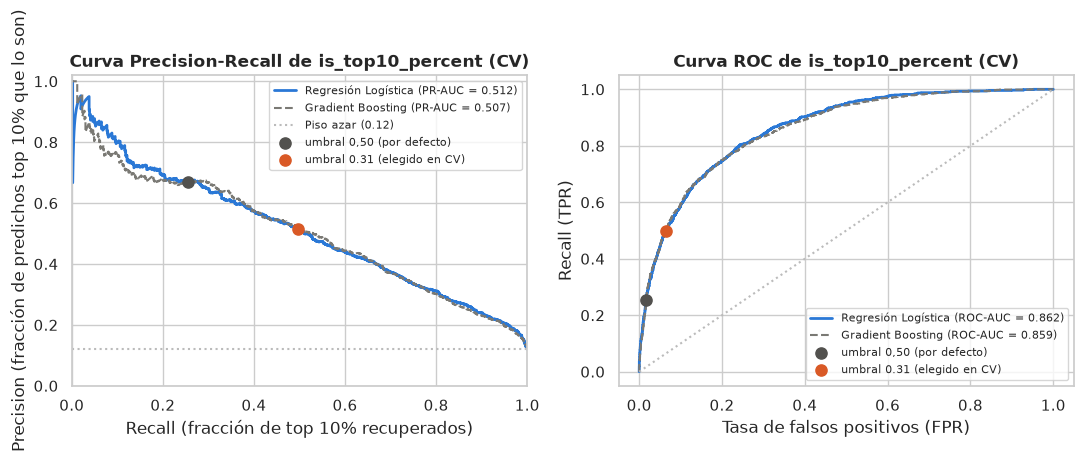

,PR-AUC (CV),ROC-AUC (CV)
Regresión Logística,0.512,0.862
Gradient Boosting,0.507,0.859


In [22]:
# Curvas Precision-Recall y ROC en validación cruzada (probabilidades fuera de muestra de X_train)
proba_cv_log = proba_oof["Logística sin balancear"]
proba_cv_hgb = proba_oof["Boosting sin balancear"]
p_final      = proba_oof[NOMBRE_FINAL]
u_final      = tabla_desbalance.loc[NOMBRE_FINAL, "umbral óptimo (CV)"]

ap_hgb, auc_hgb = average_precision_score(y_clf_train, proba_cv_hgb), roc_auc_score(y_clf_train, proba_cv_hgb)
ap_log, auc_log = average_precision_score(y_clf_train, proba_cv_log), roc_auc_score(y_clf_train, proba_cv_log)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

pr_p_log, pr_r_log, _ = precision_recall_curve(y_clf_train, proba_cv_log)
pr_p_hgb, pr_r_hgb, _ = precision_recall_curve(y_clf_train, proba_cv_hgb)
ax1.plot(pr_r_log, pr_p_log, color="#2a78d6", lw=2,   label=f"Regresión Logística (PR-AUC = {ap_log:.3f})")
ax1.plot(pr_r_hgb, pr_p_hgb, color="#7a7974", lw=1.5, ls="--", label=f"Gradient Boosting (PR-AUC = {ap_hgb:.3f})")
ax1.axhline(y_clf_train.mean(), color="#bbbbbb", ls=":", label=f"Piso azar ({y_clf_train.mean():.2f})")

fpr_log, tpr_log, _ = roc_curve(y_clf_train, proba_cv_log)
fpr_hgb, tpr_hgb, _ = roc_curve(y_clf_train, proba_cv_hgb)
ax2.plot(fpr_log, tpr_log, color="#2a78d6", lw=2,   label=f"Regresión Logística (ROC-AUC = {auc_log:.3f})")
ax2.plot(fpr_hgb, tpr_hgb, color="#7a7974", lw=1.5, ls="--", label=f"Gradient Boosting (ROC-AUC = {auc_hgb:.3f})")
ax2.plot([0, 1], [0, 1], color="#bbbbbb", ls=":")

# Marcamos sobre el modelo elegido el umbral por defecto (0,50) y el elegido por CV
es_pos = y_clf_train.values == 1
for u_val, col_u, etiq_u in [(0.50, "#52514e", "umbral 0,50 (por defecto)"), (u_final, "#d95926", f"umbral {u_final:.2f} (elegido en CV)")]:
    pred_u = p_final >= u_val
    rec, prec, fpr = pred_u[es_pos].mean(), es_pos[pred_u].mean(), pred_u[~es_pos].mean()
    ax1.scatter(rec, prec, color=col_u, zorder=4, s=65, label=etiq_u)
    ax2.scatter(fpr, rec,  color=col_u, zorder=4, s=65, label=etiq_u)

ax1.set_title("Curva Precision-Recall de is_top10_percent (CV)", weight="bold")
ax1.set_xlabel("Recall (fracción de top 10% recuperados)")
ax1.set_ylabel("Precision (fracción de predichos top 10% que lo son)")
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1.02); ax1.legend(fontsize=8)

ax2.set_title("Curva ROC de is_top10_percent (CV)", weight="bold")
ax2.set_xlabel("Tasa de falsos positivos (FPR)")
ax2.set_ylabel("Recall (TPR)")
ax2.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

display(pd.DataFrame({"PR-AUC (CV)": [ap_log, ap_hgb], "ROC-AUC (CV)": [auc_log, auc_hgb]},
                   index=["Regresión Logística", "Gradient Boosting"]).round(3))

**Tres conclusiones clave de la tabla y las curvas de la Sección 3.3:**
1. **Cuánto aporta realmente el umbral frente a la grilla (y qué pasa al combinar `class_weight="balanced"` + umbral):**
   - En la grilla de 3.2 (con umbral fijo `0,50`), `Boosting class_weight=balanced` ya alcanzaba **`0,703`**. Al optimizar el umbral sobre los modelos sin balancear (`umbral = 0,30–0,31`), `Boosting sin balancear` sube de `0,693` a **`0,721 ± 0,012`** en CV anidada (una ganancia neta realista de **`+0,018` puntos** sobre el mejor de la grilla, no `4` puntos).
   - También probamos combinar `class_weight="balanced"` + ajuste de umbral: el optimizador sube el umbral a `0,64` (en `Boosting`) y `0,70` (en `Logística`) para deshacer el empujón de `7,3×` en los pesos, llegando a `0,714–0,716`, levemente por debajo de calibrar directamente el umbral sobre las probabilidades sin distorsionar (`0,720–0,721`).
2. **Por qué gana la `Regresión Logística` al aplicar la regla del instructivo:**
   - Una vez que cada modelo usa su umbral óptimo elegido en CV (`~0,30`), **`Regresión Logística sin balancear (C=10.0)` obtiene `0,720 ± 0,018`** y **`Gradient Boosting sin balancear (lr=0.10, max_iter=100, max_leaf_nodes=15)` obtiene `0,721 ± 0,012`**.
   - En la **comparación pareada fold a fold**, la diferencia `Boosting − Logística` es de apenas **`+0,0011 ± 0,0102`** (diez veces menor que el desvío, ganando sólo en `3 de 5` folds; y en `StratifiedGroupKFold` por revista la `Regresión Logística` incluso queda arriba: **`0,713 ± 0,040` vs `0,707 ± 0,031`**, diferencia `-0,006 ± 0,015`).
   - Las curvas en validación cruzada explican por qué: tanto en **Precision-Recall** (`PR-AUC = 0,512` en `Logística` vs `0,507` en `Boosting`, frente a un piso de `0,120`) como en **ROC** (`ROC-AUC = 0,862` vs `0,859`), ambos modelos ordenan los artículos casi igual. `Boosting` sólo parecía superior en 3.1 (`0,687` vs `0,653`) porque con el umbral arbitrario de `0,50` era menos conservador (`recall = 0,339` vs `0,255`).
   - Siguiendo la regla explícita del instructivo (*«si el complejo no le gana al simple por más que el desvío, se queda el simple»*), **elegimos la `Regresión Logística` envuelta en `TunedThresholdClassifierCV` (que aprende el umbral `0,30` adentro de `fit`) como clasificador final**.

---

### 3.4 El modelo final de Clasificación, leído sobre el Test (tocado una sola vez)

Entrenamos `modelo_clf_final` (`TunedThresholdClassifierCV` con `Regresión Logística C=10.0`, cuyo umbral óptimo aprendido en `X_train` es **`0,30`**) y lo aplicamos una única vez sobre `X_test` para comparar las estrategias de decisión, mostrar las **matrices de confusión** (conteos, normalizada por fila y normalizada por columna), inspeccionar los errores concretos y leer en qué columnas se apoya.

In [23]:
# ============================================================
# 3.4 Evaluación única sobre X_test en Clasificación
# ============================================================
# El modelo final ES el objeto TunedThresholdClassifierCV: el umbral elegido por CV viaja adentro
# del modelo (predict ya lo aplica), así la aplicación de la Entrega 4 no tiene que recordarlo aparte.
modelo_clf_final = TunedThresholdClassifierCV(
    candidatos[NOMBRE_FINAL], scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES,
).fit(X_train, y_clf_train)
UMBRAL = modelo_clf_final.best_threshold_

NOMBRE_OTRO = "Boosting sin balancear" if NOMBRE_FINAL.startswith("Logística") else "Logística sin balancear"
modelo_clf_otro = TunedThresholdClassifierCV(
    candidatos[NOMBRE_OTRO], scoring="f1_macro", cv=cv_clf, thresholds=UMBRALES,
).fit(X_train, y_clf_train)

log_ent = clone(candidatos["Logística sin balancear"]).fit(X_train, y_clf_train)          # para leer coeficientes
log_bal = clone(candidatos["Logística class_weight=balanced"]).fit(X_train, y_clf_train)
hgb_bal = clone(candidatos["Boosting class_weight=balanced"]).fit(X_train, y_clf_train)

proba_test_final = modelo_clf_final.predict_proba(X_test)[:, 1]
pred_clf_test    = modelo_clf_final.predict(X_test)

def metricas_test_clf(pred):
    pred = np.asarray(pred)
    es_top = (y_clf_test == 1).values
    return {
        "f1_macro (Test)":    f1_score(y_clf_test, pred, average="macro"),
        "f1 top 10% (Test)":  f1_score(y_clf_test, pred),
        "recall top 10%":     pred[es_top].mean(),
        "precision top 10%":  (y_clf_test.values[pred == 1] == 1).mean() if (pred == 1).any() else 0.0,
        "accuracy (Test)":    (pred == y_clf_test.values).mean(),
    }

tabla_final_clf = pd.DataFrame({
    "Piso (siempre False)":                            metricas_test_clf(np.zeros(len(y_clf_test), dtype=int)),
    f"{NOMBRE_FINAL} (umbral 0,50)":                   metricas_test_clf((proba_test_final >= 0.50).astype(int)),
    "Logística class_weight=balanced (umbral 0,50)":   metricas_test_clf(log_bal.predict(X_test)),
    "Boosting class_weight=balanced (umbral 0,50)":    metricas_test_clf(hgb_bal.predict(X_test)),
    f"{NOMBRE_OTRO} (umbral {modelo_clf_otro.best_threshold_:.2f}, referencia)": metricas_test_clf(modelo_clf_otro.predict(X_test)),
    f"{NOMBRE_FINAL} (umbral {UMBRAL:.2f} — Elegido)": metricas_test_clf(pred_clf_test),
}).T.round(3)

display(tabla_final_clf)

,f1_macro (Test),f1 top 10% (Test),recall top 10%,precision top 10%,accuracy (Test)
Piso (siempre False),0.468,0.000,0.000,0.000,0.880
"Logística sin balancear (umbral 0,50)",0.635,0.331,0.233,0.574,0.887
"Logística class_weight=balanced (umbral 0,50)",0.613,0.407,0.791,0.274,0.724
"Boosting class_weight=balanced (umbral 0,50)",0.667,0.441,0.594,0.351,0.819
"Boosting sin balancear (umbral 0.30, referencia)",0.691,0.457,0.462,0.453,0.869
Logística sin balancear (umbral 0.30 — Elegido),0.689,0.453,0.450,0.455,0.870


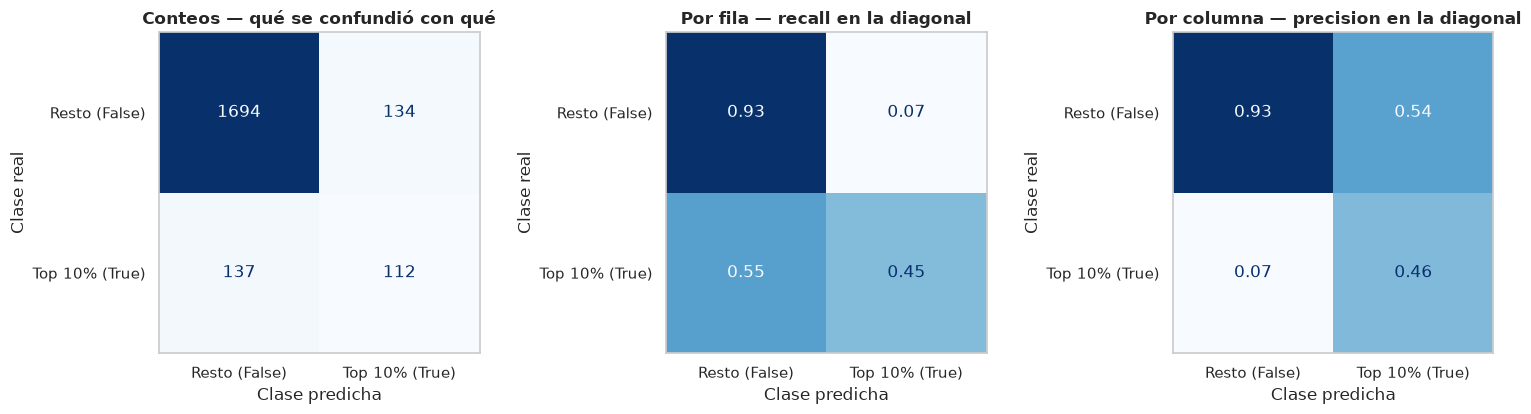

,precision,recall,f1-score,support
Resto (False),0.925,0.927,0.926,1828.00
Top 10% (True),0.455,0.450,0.453,249.00
accuracy,0.870,0.870,0.870,0.87
macro avg,0.690,0.688,0.689,2077.00
weighted avg,0.869,0.870,0.869,2077.00


In [24]:
# Matrices de confusión del modelo elegido (con su umbral ajustado en CV) sobre X_test:
# 1) Conteos, 2) Normalizada por fila (recall en la diagonal), 3) Normalizada por columna (precision en la diagonal)
etiquetas_clase = ["Resto (False)", "Top 10% (True)"]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.3))

ConfusionMatrixDisplay.from_predictions(
    y_clf_test, pred_clf_test, display_labels=etiquetas_clase,
    ax=axes[0], cmap="Blues", colorbar=False,
)
axes[0].set_title("Conteos — qué se confundió con qué", weight="bold")

ConfusionMatrixDisplay.from_predictions(
    y_clf_test, pred_clf_test, display_labels=etiquetas_clase,
    ax=axes[1], cmap="Blues", colorbar=False, normalize="true", values_format=".2f",
)
axes[1].set_title("Por fila — recall en la diagonal", weight="bold")

ConfusionMatrixDisplay.from_predictions(
    y_clf_test, pred_clf_test, display_labels=etiquetas_clase,
    ax=axes[2], cmap="Blues", colorbar=False, normalize="pred", values_format=".2f",
)
axes[2].set_title("Por columna — precision en la diagonal", weight="bold")

for ax in axes:
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.grid(False)

plt.tight_layout()
plt.show()

# Reporte completo por clase
reporte_clf = pd.DataFrame(
    classification_report(y_clf_test, pred_clf_test, target_names=etiquetas_clase, output_dict=True)
).T.round(3)
display(reporte_clf)

In [25]:
# ============================================================
# Inspección de confusiones concretas del clasificador en X_test
# ============================================================
df_test_inspeccion = df.loc[X_test.index, [
    "title", "primary_location_source_display_name", "primary_topic_subfield_display_name",
    "cited_by_count", "is_top10_percent", "source_pre_cites_per_work",
    "referenced_works_count", "last_author_pre_cites",
]].copy()
df_test_inspeccion["prob_top10"] = proba_test_final.round(3)
df_test_inspeccion["pred_top10"] = pred_clf_test.astype(bool)

print("=== Falsos Positivos con mayor probabilidad predicha (el modelo dijo Top 10%, pero no lo fueron) ===")
fp = df_test_inspeccion[(~df_test_inspeccion["is_top10_percent"]) & (df_test_inspeccion["pred_top10"])].sort_values("prob_top10", ascending=False)
display(fp.head(5))

print("=== Falsos Negativos con menor probabilidad predicha (eran Top 10%, pero el modelo dijo Resto) ===")
fn = df_test_inspeccion[(df_test_inspeccion["is_top10_percent"]) & (~df_test_inspeccion["pred_top10"])].sort_values("prob_top10", ascending=True)
display(fn.head(5))

=== Falsos Positivos con mayor probabilidad predicha (el modelo dijo Top 10%, pero no lo fueron) ===


,title,primary_location_source_display_name,primary_topic_subfield_display_name,cited_by_count,is_top10_percent,source_pre_cites_per_work,referenced_works_count,last_author_pre_cites,prob_top10,pred_top10
8308,Rational Design of Nanogels for Overcoming the...,Angewandte Chemie International Edition,Biomaterials,77,False,108.363108,163,72508.0,0.878,True
5428,Heterostructures in two-dimensional colloidal ...,Nano Research,Materials Chemistry,42,False,76.665049,242,2677.0,0.865,True
1,Asymmetric MXene/monolayer transition metal di...,npj Computational Materials,Materials Chemistry,42,False,158.483146,81,11417.0,0.845,True
9585,Antioxidants and Nanotechnology: Promises and ...,Advanced Healthcare Materials,Biomaterials,112,False,56.060474,320,8796.0,0.794,True
1134,Chemically Modified Natural Polymer-Based Ther...,ACS Biomaterials Science & Engineering,Biomaterials,50,False,46.344828,315,NaN,0.785,True


=== Falsos Negativos con menor probabilidad predicha (eran Top 10%, pero el modelo dijo Resto) ===


,title,primary_location_source_display_name,primary_topic_subfield_display_name,cited_by_count,is_top10_percent,source_pre_cites_per_work,referenced_works_count,last_author_pre_cites,prob_top10,pred_top10
9932,"Thermal, Biodegradability and Water Barrier Pr...",Journal of Biobased Materials and Bioenergy,Biomaterials,129,True,12.548352,0,809.0,0.002,False
11771,"Bilayer Graphene’s Wicked, Twisted Road",Physics,Materials Chemistry,76,True,2.626224,25,NaN,0.002,False
1820,Effect of gamma irradiation on microstructure ...,Modern Physics Letters B,Materials Chemistry,43,True,6.163782,31,953.0,0.004,False
11802,Zinc Oxide Nano Particles Integrated Kenaf/Uns...,JOURNAL OF RENEWABLE MATERIALS,Polymers and Plastics,54,True,17.496350,0,2515.0,0.004,False
5367,Effects of NiO content on the microstructure a...,Science and Engineering of Composite Materials,General Materials Science,28,True,8.258951,17,NaN,0.006,False


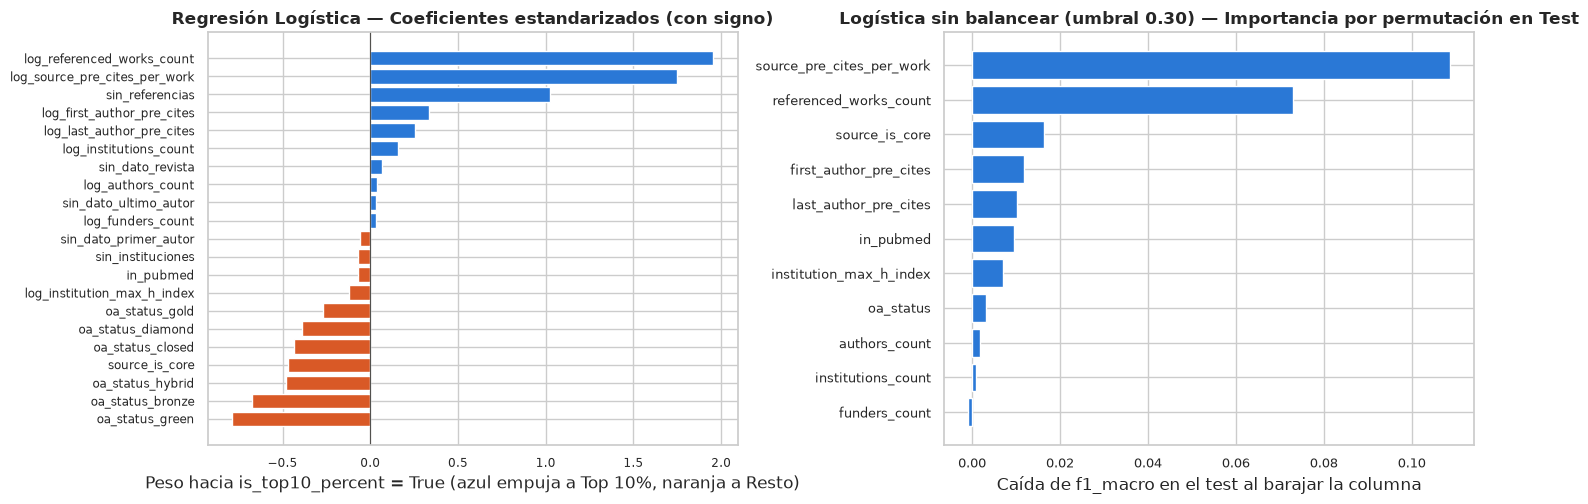

,caída de f1_macro al permutar
source_pre_cites_per_work,0.1087
referenced_works_count,0.0729
source_is_core,0.0164
first_author_pre_cites,0.0117
last_author_pre_cites,0.0103
in_pubmed,0.0094
institution_max_h_index,0.0071
oa_status,0.0031
authors_count,0.0018
institutions_count,0.0009


,oa_status_green,oa_status_bronze,oa_status_hybrid,source_is_core,oa_status_closed,oa_status_diamond,oa_status_gold,log_institution_max_h_index,in_pubmed,sin_instituciones,sin_dato_primer_autor,log_funders_count,sin_dato_ultimo_autor,log_authors_count,sin_dato_revista,log_institutions_count,log_last_author_pre_cites,log_first_author_pre_cites,sin_referencias,log_source_pre_cites_per_work,log_referenced_works_count
coeficiente Logística (estandarizado),-0.79,-0.672,-0.483,-0.467,-0.433,-0.389,-0.27,-0.123,-0.071,-0.07,-0.057,0.031,0.033,0.036,0.065,0.158,0.256,0.335,1.025,1.746,1.956


Correlación de Spearman entre las dos variables principales y source_is_core:


,source_pre_cites_per_work,referenced_works_count,source_is_core
source_pre_cites_per_work,1.000,0.599,0.597
referenced_works_count,0.599,1.000,0.514
source_is_core,0.597,0.514,1.000


In [26]:
# ============================================================
# 3.5 En qué se apoya el clasificador: Coeficientes (Logística) e Importancia por Permutación (modelo elegido)
# ============================================================
nombres_features_clf = [n.split("__")[-1] for n in log_ent[:-1].get_feature_names_out()]
coefs_log = pd.Series(log_ent[-1].coef_[0], index=nombres_features_clf).sort_values()

pi_clf = permutation_importance(
    modelo_clf_final, X_test, y_clf_test,   # predict aplica el umbral elegido
    scoring="f1_macro", n_repeats=10, random_state=SEMILLA, n_jobs=-1,
)
imp_perm_clf = pd.Series(pi_clf.importances_mean, index=X_test.columns).loc[COLS_BASE_INPUT].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Panel 1: Coeficientes de la Regresión Logística
colores_log = np.where(coefs_log.values >= 0, "#2a78d6", "#d95926")
axes[0].barh(coefs_log.index, coefs_log.values, color=colores_log)
axes[0].axvline(0, color="#52514e", lw=0.8)
axes[0].set_title("Regresión Logística — Coeficientes estandarizados (con signo)", weight="bold")
axes[0].set_xlabel("Peso hacia is_top10_percent = True (azul empuja a Top 10%, naranja a Resto)")
axes[0].tick_params(labelsize=8.5)

# Panel 2: Importancia por permutación en f1_macro (Gradient Boosting)
axes[1].barh(imp_perm_clf.index, imp_perm_clf.values, color="#2a78d6")
axes[1].set_title(f"{NOMBRE_FINAL} (umbral {UMBRAL:.2f}) — Importancia por permutación en Test", weight="bold")
axes[1].set_xlabel("Caída de f1_macro en el test al barajar la columna")
axes[1].tick_params(labelsize=9)

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "caída de f1_macro al permutar": imp_perm_clf.sort_values(ascending=False).round(4),
}))
display(coefs_log.round(3).to_frame("coeficiente Logística (estandarizado)").T)

# Chequeo de colinealidad entre las dos variables más importantes (Práctica 1, sección 5.5)
print("Correlación de Spearman entre las dos variables principales y source_is_core:")
display(df[["source_pre_cites_per_work", "referenced_works_count", "source_is_core"]].corr(method="spearman").round(3))

**Lectura del modelo final de Clasificación:**

1. **El efecto del umbral en el test y la confirmación del empate técnico:** en `X_test` (mirado una sola vez), pasar del umbral por defecto (`0,50`) al umbral `0,30` aprendido adentro de `TunedThresholdClassifierCV` sube el `f1_macro` de la `Regresión Logística` de **`0,635` a `0,689`** (y el F1 de la clase `top 10 %` de `0,331` a **`0,453`**, casi duplicando el *recall* de `0,233` a **`0,450`** —recupera `112` de los `249` artículos `top 10 %` del test— con una *precision* de **`0,455`** y `accuracy = 0,870`, frente al `0,468` del piso). El `Gradient Boosting` con umbral `0,30` (incluido en la tabla como referencia) da **`0,691`** (`0,002` de diferencia), confirmando en el test que el modelo simple iguala al complejo.
2. **Explicación de los Falsos Positivos y Falsos Negativos desde el dominio:**
   - **Falsos Positivos (`134` casos de `1.828` negativos, especificidad de `92,7 %`):** la tabla muestra artículos publicados en revistas de altísimo prestigio (`source_pre_cites_per_work` entre `46` y `158`, como *Angewandte Chemie International Edition*, *Nano Research*, *npj Computational Materials*, *Advanced Healthcare Materials* o *ACS Biomaterials Science & Engineering*), con bibliografías extensas (`81` a `320` referencias) y líderes de grupo muy citados, que recibieron entre **`42` y `112` citas reales**: tuvieron un impacto absoluto alto, pero en subcampos muy competitivos (*Biomaterials*, *Materials Chemistry*) no alcanzaron el corte del `top 10 %`.
   - **Falsos Negativos (`137` casos de `249` positivos):** reúnen tres situaciones claras del dominio: (a) éxitos inesperados en revistas de prestigio bajo o moderado (`source_pre_cites_per_work` de `2,6` a `17,5`, como *Physics* o *Modern Physics Letters B*); (b) artículos con metadatos de referencias incompletos en OpenAlex (`referenced_works_count == 0`, como el de *Journal of Biobased Materials and Bioenergy* con `129` citas); y (c) el solapamiento del indicador `is_top10_percent` documentado en la Entrega 2: como OpenAlex normaliza por subtema fino, hay artículos con `28` citas que son `top 10 %` en su nicho mientras otros con `112` citas quedan afuera.
3. **En qué se apoya el clasificador (y la trampa de la colinealidad de la Práctica 1 §5.5):**
   - Por **importancia por permutación** en el test, las dos columnas que sostienen la clasificación son **`source_pre_cites_per_work`** (barajarla hace caer el `f1_macro` en **`0,109` puntos**) y **`referenced_works_count`** (**`0,073` puntos**), seguidas de lejos por `source_is_core` (`0,016`), `first_author_pre_cites` (`0,012`), `last_author_pre_cites` (`0,010`), `in_pubmed` (`0,009`) e `institution_max_h_index` (`0,007`).
   - En los **coeficientes estandarizados** de la `Regresión Logística`, empujan con fuerza hacia `top 10 %` `log_referenced_works_count` (**`+1,956`**), `log_source_pre_cites_per_work` (**`+1,746`**) y `sin_referencias` (**`+1,025`**, que compensa el cero cuando faltan los metadatos de referencias), seguidos por `log_first_author_pre_cites` (`+0,335`), `log_last_author_pre_cites` (`+0,256`) y `log_institutions_count` (`+0,158`).
   - En cambio, `source_is_core` recibe un coeficiente negativo (**`-0,467`**). No es que publicar en una revista *core* reduzca la probabilidad de ser `top 10 %` (en la Entrega 2 vimos que por sí sola multiplica la tasa de `top 10 %`): es que correlaciona **`0,597`** con `source_pre_cites_per_work` y **`0,514`** con `referenced_works_count`. Cuando el modelo lineal ya suma `+1,746` por el prestigio continuo de la revista, `source_is_core` actúa como ajuste de borde para revistas *core* de impacto medio, y al barajarla en permutación se rompe esa compensación (`0,016` de caída).

---

## 4. Síntesis y respuestas directas a las preguntas de la Entrega 3

Cerramos el notebook dejando respondidas, con los números exactos obtenidos arriba, las **seis preguntas de defensa** planteadas en el instructivo:

| Pregunta del instructivo | Respuesta fundamentada en este notebook |
|---|---|
| **1. ¿Por qué esa métrica? ¿Qué error es más caro en tu problema y si la métrica lo ve?** | En **Regresión** usamos **MAE** sobre `log(1 + cited_by_count)` (acompañado de $R^2$) porque se lee en las unidades del objetivo y pesa igual a todos los artículos, evitando que el `1 %` de artículos con más de `260` citas domine la pérdida como haría el RMSE. En **Clasificación** (`is_top10_percent`, con `12,0 %` de positivos) la *accuracy* esconde a la clase chica (contestar siempre `False` da `88,0 %` de *accuracy*); por eso declaramos **`f1_macro`**, que promedia ambas clases `50/50` y penaliza por igual perder artículos destacados (*recall*) o llenar la predicción de falsas alarmas (*precision*). |
| **2. ¿Cuánto le gana tu modelo al piso, y si eso es mucho o poco para lo que querés hacer con él?** | En **Regresión**, el modelo elegido (`HistGradientBoostingRegressor`) baja el MAE en el test de **`1,123` (piso) a `0,698`** (una reducción de `0,425` puntos, más de 30 veces el desvío entre folds; notamos además que el `0,698` del test queda `0,015` por encima del `0,683 ± 0,011` de CV, un corrimiento que afecta por igual a `Ridge` —`0,707` a `0,713`— por casos de cola en `X_test`) y explica el **`59,2 %` de la varianza ($R^2 = 0,592$)**. En **Clasificación**, el modelo elegido (`Regresión Logística C=10` con umbral `0,30` adentro de `TunedThresholdClassifierCV`) pasa de **`0,468` (piso) a `0,689` de `f1_macro`** en el test (`0,720 ± 0,018` en CV anidada) y de `0,000` a **`0,453`** en el F1 de la clase `top 10 %`. Para la **Entrega 4**, ambos objetos (`Pipeline` y `TunedThresholdClassifierCV`) quedan listos para predecir con `predict()` sobre los metadatos iniciales del artículo. |
| **3. ¿Por qué los pedazos de la validación se arman así, y qué le pasaría al número si los armaras al azar (o por grupo)?** | Como todos los artículos son de `2019` y el mes no influye (H4: $\rho = -0,035$), no aplica corte temporal. Nuestro uso previsto es predecir artículos dentro del catálogo conocido de revistas de Ciencia de Materiales (el **`87,6 %`** de `X_test` pertenece a revistas presentes en `X_train`), por lo que la validación que imita el uso es `KFold` / `StratifiedKFold` por artículo. Al probar qué pasa si se evalúa sobre revistas nunca vistas (`GroupKFold` / `StratifiedGroupKFold` sobre las `2.297` revistas), `Ridge` casi no cambia (`0,707` a **`0,709`**), pero `Gradient Boosting` sube de **`0,686` a `0,701`** (`+0,015`, más de un desvío), achicando la ventaja pareada sobre `Ridge` de **`0,0208 ± 0,0052` (`5/5` folds)** en `KFold` a **`0,0080 ± 0,0073`** en `GroupKFold`. Es decir: para revistas conocidas gana `Boosting`; si se usara sobre revistas nuevas, por la regla del desvío convendría `Ridge`. |
| **4. ¿Por qué ese modelo y no uno más complejo (o más simple), con la diferencia y el desvío a la vista?** | Aplicamos la regla del instructivo (*«si el complejo no le gana al simple por más que el desvío, se queda el simple»*) en ambos objetivos: en **Regresión**, `Gradient Boosting` (`0,683 ± 0,011`) le gana a `Ridge` (`0,707 ± 0,009`) por **`0,024` de MAE** (`+0,021 ± 0,005` pareado, `5/5` folds) y empata con `Random Forest` (`0,681 ± 0,011`), por lo que se justifica el modelo complejo; además descartamos las 5 columnas en observación porque juntas bajan apenas `0,012` de MAE en `Boosting` (`1,2 %` en factor multiplicativo) a costa de casi triplicar las columnas (`21` a `56`). En cambio, en **Clasificación**, una vez ajustado el umbral en CV (`TunedThresholdClassifierCV`, umbral `0,30`), la **`Regresión Logística` (`0,720 ± 0,018`) empata con `Gradient Boosting` (`0,721 ± 0,012`)**, con una diferencia pareada de **`+0,001 ± 0,010`** (diez veces menor que el desvío; y en `StratifiedGroupKFold` gana la logística `0,713` vs `0,707`), por lo que **se queda el modelo simple (`Regresión Logística`)**. |
| **5. Una confusión concreta del modelo, o un tramo donde erra mucho, y una explicación desde tu dominio.** | En **Regresión**, el modelo es muy preciso entre `5` y `49` citas (`MAE` de `0,52` a `0,67`), pero subestima el tramo de **`100+` citas** (mediana real `164` vs predicha `57,8`, `MAE = 1,338`): las variables previas miden el piso de visibilidad que dan la revista, la bibliografía y el grupo, pero un *hit* de `1.000` citas depende del hallazgo científico puntual. En **Clasificación**, los **`134` Falsos Positivos** son artículos en revistas de élite (*Angewandte Chemie*, *Nano Research*, *npj Computational Materials*, con `46–158` citas previas por trabajo) que recibieron `42–112` citas pero no llegaron al corte del `top 10 %` de su subtema; y los **`137` Falsos Negativos** combinan éxitos inesperados en revistas chicas, artículos con `referenced_works_count == 0` por metadatos faltantes y el solapamiento del corte de `is_top10_percent` de OpenAlex entre subtemas finos. |
| **6. La columna que más pesa, y qué hiciste para descartar que sea una fuga.** | Las dos columnas que más pesan son **`referenced_works_count`** (`+0,238` en MAE y `+0,073` en `f1_macro` al permutar) y **`source_pre_cites_per_work`** (`+0,230` en MAE y `+0,109` en `f1_macro`). Descartamos fuga en **todas** las columnas con evidencia empírica (Secciones 2.3 y 2.5 bis): (1) **`referenced_works_count`** queda fija en el PDF al publicar (`100 %` son `type == "article"`), los ceros por metadatos faltantes se aíslan con `sin_referencias`, y **dentro de la misma revista** correlaciona positivamente con las citas en el **`90,6 %` de las revistas** (mediana $\rho = 0,277$); (2) **`source_pre_cites_per_work`** se calculó sólo con trabajos de **2012–2018** (previos a 2019); (3) en **`oa_status`**, pasar `green` y `bronze` a `closed` mueve el MAE apenas `+0,001` a `+0,003`; y (4) en **`in_pubmed`** (que es `0 %` o `100 %` por revista en el `88,3 %` de las revistas) e **`institution_max_h_index`**, quitarlas por ablación en CV cambia el MAE en **`+0,0006 ± 0,0007`** y **`+0,0013 ± 0,0033`**, confirmando que el modelo no depende de información posterior a la publicación. |